# LendingClub application PD scorecard (36-month loans, out-of-time 2016)

**What this notebook does.** It builds a probability-of-default (PD) model that a bank could run *at the moment a
borrower applies*, using only information that exists at application time, and then evaluates it on a later
time period the model never saw. It follows the usual 8-stage credit-risk development path:
framing, data checks, univariate WoE/IV, multicollinearity, a logistic ladder (plain, L1, L2, ElasticNet, WoE scorecard),
challenger models (XGBoost tuned and monotone-constrained), comparison with a frozen champion rule, and the business
layer (master scale, cut-off, monitoring).

**Plain-English summary.** We look at about 3 years of past loans, learn which application details go with people not
paying back *within their first year*, then check on loans from the *following year* whether the ranking still works. The headline number is the
out-of-time Gini (0 = no better than a coin toss, 1 = perfect). On public LendingClub data with application-time
information only, a Gini of roughly 0.3 to 0.45 is realistic, and that is what we report.

**Scope notes up front.** (1) Only *accepted* loans are in the data, so there is no reject inference.
(2) The target is a **12-month performance window** (90+ days past due within 12 months of issue, proxied from the last-payment date; see Stage 1).
Every 2013-2016 loan has a complete 12-month window by the Mar-2019 data cut, so **no loan is dropped as "unresolved" and nothing is right-censored**. An earlier
version of this project used a lifetime label on resolved loans only; that dropped every 2016 loan still open at the data cut (a large share), which inflated the 2016 bad rate and made the model look
under-calibrated. We keep that old label as a sensitivity check rather than hiding it. (3) Grade, sub-grade and interest rate are
LendingClub's own risk outputs and are deliberately **excluded** from the main models.

In [1]:
%%writefile lcpd_lib.py
"""lcpd_lib - shared code for the LendingClub application PD scorecard.

The notebook writes this exact file to disk, imports it, and copies it into artifacts/.
The Streamlit app and the tests import the same file, so training-time and serving-time
logic cannot drift apart.  Everything the app needs at serve time is stored as plain JSON
(bin tables, coefficients, prep parameters) - no sklearn pickles are needed to score.
"""
from __future__ import annotations

import json
import math
from pathlib import Path

import numpy as np
import pandas as pd

# --------------------------------------------------------------------------------------
# 1. Feature dictionary (application-time information only)
# --------------------------------------------------------------------------------------
# label, group, expected sign of the effect on PD (+1 risk up when value up, -1 risk down, 0 unclear)
FEATURE_META = {
    "loan_amnt": ("Loan amount requested ($)", "Loan", +1),
    "emp_length": ("Employment length (years)", "Applicant", -1),
    "annual_inc": ("Annual income ($)", "Applicant", -1),
    "dti": ("Debt-to-income ratio (%)", "Applicant", +1),
    "loan_to_income": ("Loan amount / annual income", "Loan", +1),
    "fico": ("FICO score at application", "Bureau", -1),
    "credit_history_months": ("Credit history length (months)", "Bureau", -1),
    "delinq_2yrs": ("Delinquencies in last 2 years", "Bureau", +1),
    "inq_last_6mths": ("Credit enquiries in last 6 months", "Bureau", +1),
    "mths_since_last_delinq": ("Months since last delinquency", "Bureau", -1),
    "mths_since_last_record": ("Months since last public record", "Bureau", -1),
    "mths_since_last_major_derog": ("Months since last major derogatory", "Bureau", -1),
    "open_acc": ("Open credit lines", "Bureau", 0),
    "pub_rec": ("Public records", "Bureau", +1),
    "revol_bal": ("Revolving balance ($)", "Bureau", 0),
    "revol_util": ("Revolving utilisation (%)", "Bureau", +1),
    "total_acc": ("Total credit lines ever", "Bureau", -1),
    "collections_12_mths_ex_med": ("Collections in last 12 months", "Bureau", +1),
    "acc_now_delinq": ("Accounts currently delinquent", "Bureau", +1),
    "tot_coll_amt": ("Total collection amount ever ($)", "Bureau", +1),
    "tot_cur_bal": ("Total current balance, all accounts ($)", "Bureau", 0),
    "total_rev_hi_lim": ("Total revolving credit limit ($)", "Bureau", -1),
    "acc_open_past_24mths": ("Accounts opened in past 24 months", "Bureau", +1),
    "avg_cur_bal": ("Average balance per account ($)", "Bureau", 0),
    "bc_open_to_buy": ("Open-to-buy on bankcards ($)", "Bureau", -1),
    "bc_util": ("Bankcard utilisation (%)", "Bureau", +1),
    "chargeoff_within_12_mths": ("Charge-offs in last 12 months", "Bureau", +1),
    "delinq_amnt": ("Past-due amount owed ($)", "Bureau", +1),
    "mo_sin_old_il_acct": ("Months since oldest instalment account", "Bureau", -1),
    "mo_sin_old_rev_tl_op": ("Months since oldest revolving account", "Bureau", -1),
    "mo_sin_rcnt_rev_tl_op": ("Months since newest revolving account", "Bureau", -1),
    "mo_sin_rcnt_tl": ("Months since newest account", "Bureau", -1),
    "mort_acc": ("Mortgage accounts", "Bureau", -1),
    "mths_since_recent_bc": ("Months since newest bankcard", "Bureau", -1),
    "mths_since_recent_bc_dlq": ("Months since bankcard delinquency", "Bureau", -1),
    "mths_since_recent_inq": ("Months since latest enquiry", "Bureau", -1),
    "mths_since_recent_revol_delinq": ("Months since revolving delinquency", "Bureau", -1),
    "num_accts_ever_120_pd": ("Accounts ever 120+ days past due", "Bureau", +1),
    "num_actv_bc_tl": ("Active bankcard accounts", "Bureau", 0),
    "num_actv_rev_tl": ("Active revolving accounts", "Bureau", 0),
    "num_bc_sats": ("Satisfactory bankcard accounts", "Bureau", 0),
    "num_bc_tl": ("Bankcard accounts", "Bureau", 0),
    "num_il_tl": ("Instalment accounts", "Bureau", 0),
    "num_op_rev_tl": ("Open revolving accounts", "Bureau", 0),
    "num_rev_accts": ("Revolving accounts", "Bureau", 0),
    "num_rev_tl_bal_gt_0": ("Revolving accounts with a balance", "Bureau", +1),
    "num_sats": ("Satisfactory accounts", "Bureau", 0),
    "num_tl_120dpd_2m": ("Accounts 120+ dpd in last 2 months", "Bureau", +1),
    "num_tl_30dpd": ("Accounts 30 dpd now", "Bureau", +1),
    "num_tl_90g_dpd_24m": ("Accounts 90+ dpd in last 24 months", "Bureau", +1),
    "num_tl_op_past_12m": ("Accounts opened in past 12 months", "Bureau", +1),
    "pct_tl_nvr_dlq": ("% of accounts never delinquent", "Bureau", -1),
    "percent_bc_gt_75": ("% of bankcards over 75% used", "Bureau", +1),
    "pub_rec_bankruptcies": ("Public-record bankruptcies", "Bureau", +1),
    "tax_liens": ("Tax liens", "Bureau", +1),
    "tot_hi_cred_lim": ("Total highest credit limit ($)", "Bureau", -1),
    "total_bal_ex_mort": ("Total balance excluding mortgage ($)", "Bureau", +1),
    "total_bc_limit": ("Total bankcard limit ($)", "Bureau", -1),
    "total_il_high_credit_limit": ("Total instalment high credit limit ($)", "Bureau", 0),
}
NUMERIC_FEATURES = list(FEATURE_META)
CATEGORICAL_FEATURES = ["home_ownership", "verification_status", "purpose"]
CAT_LABELS = {"home_ownership": "Home ownership", "verification_status": "Income verification",
              "purpose": "Loan purpose"}
ALL_FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
LABELS = {k: v[0] for k, v in FEATURE_META.items()} | CAT_LABELS
EXPECTED_SIGN = {k: v[2] for k, v in FEATURE_META.items()}
GROUPS = {k: v[1] for k, v in FEATURE_META.items()} | {c: "Applicant" for c in CATEGORICAL_FEATURES}

# raw columns the loader must read from the LendingClub file
RAW_READ_COLS = sorted(set(
    ["id", "issue_d", "loan_status", "term", "application_type", "last_pymnt_d", "int_rate", "grade", "sub_grade",
     "earliest_cr_line", "fico_range_low", "fico_range_high", "emp_length", "loan_amnt"]
    + [c for c in NUMERIC_FEATURES if c not in ("emp_length", "loan_to_income", "fico", "credit_history_months")]
    + CATEGORICAL_FEATURES))

BAD_STATUS = ["Charged Off", "Default", "Does not meet the credit policy. Status:Charged Off"]
GOOD_STATUS = ["Fully Paid", "Does not meet the credit policy. Status:Fully Paid"]

# ---- default definition: 12-month performance window (no right-censoring) ---------------------------
# The file has only a snapshot status (no monthly delinquency history), so "90+ days past due within 12 months of issue"
# is proxied from two fields: final status in BAD_STATUS AND the month of the last payment made (months on book).
# A borrower whose last payment fell in month k has missed instalments k+1, k+2, k+3 by month k+3, so k <= 9 means 90+ DPD by month 12.
PERF_WINDOW_MONTHS = 12
BAD_MAX_MOB = 9


def months_on_book_last_payment(issue_d, last_pymnt_d):
    """Whole months from issue to the last payment received (0 when no payment was ever made)."""
    issue_d, last_pymnt_d = pd.to_datetime(issue_d), pd.to_datetime(last_pymnt_d)
    mob = (last_pymnt_d.dt.year - issue_d.dt.year) * 12 + (last_pymnt_d.dt.month - issue_d.dt.month)
    return mob.fillna(0).astype("float64")


def label_12m(loan_status, mob, max_mob=BAD_MAX_MOB):
    """1 = ended in Charged Off / Default AND stopped paying early enough to be 90+ DPD within the 12-month window; else 0."""
    return (pd.Series(loan_status).isin(BAD_STATUS).values & (np.asarray(mob) <= max_mob)).astype("float64")

# plain-English phrase for reason codes (used when the variable costs the applicant points)
REASON_PHRASES = {
    "fico": "Credit score (FICO) is lower than the best-scoring applicants",
    "dti": "Debts are high relative to income",
    "annual_inc": "Annual income is lower",
    "loan_amnt": "Loan amount requested is high",
    "loan_to_income": "Loan is large relative to income",
    "revol_util": "Credit cards are heavily used (high utilisation)",
    "bc_util": "Bankcards are heavily used (high utilisation)",
    "inq_last_6mths": "Several recent credit enquiries",
    "credit_history_months": "Short credit history",
    "delinq_2yrs": "Recent delinquencies on file",
    "pub_rec": "Public record on file",
    "acc_open_past_24mths": "Many new accounts opened recently",
    "tot_cur_bal": "Total balances are low relative to the best applicants",
    "mort_acc": "No or few mortgage accounts",
    "purpose": "Loan purpose carries higher historical risk",
    "home_ownership": "Home-ownership status carries higher historical risk",
    "verification_status": "Income verification status carries higher historical risk",
    "emp_length": "Shorter employment history",
    "total_rev_hi_lim": "Lower total revolving credit limit",
    "num_tl_op_past_12m": "Several accounts opened in the last 12 months",
    "mths_since_recent_inq": "A very recent credit enquiry",
    "num_rev_tl_bal_gt_0": "Many revolving accounts carry a balance",
    "total_bc_limit": "Lower total bankcard limit",
    "avg_cur_bal": "Average account balance differs from the best applicants",
    "pct_tl_nvr_dlq": "Lower share of never-delinquent accounts",
    "mo_sin_rcnt_tl": "Opened an account very recently",
    "mo_sin_old_rev_tl_op": "Newer oldest revolving account",
    "open_acc": "Number of open credit lines",
    "total_acc": "Number of total credit lines",
}


def reason_phrase(var):
    return REASON_PHRASES.get(var, f"{LABELS.get(var, var)} is less favourable than the best-scoring applicants")


# --------------------------------------------------------------------------------------
# 2. Raw -> engineered features (shared by training and the app)
# --------------------------------------------------------------------------------------
def parse_emp_length(s: pd.Series) -> pd.Series:
    s = s.astype("string").str.strip()
    out = s.str.extract(r"(\d+)")[0].astype("float64")
    out = out.where(~s.str.startswith("<", na=False), 0.0)
    return out.astype("float64")


def engineer(raw: pd.DataFrame) -> pd.DataFrame:
    """Return the modelling frame (ALL_FEATURES) from raw LendingClub-style columns.

    Cleaning rules (all documented in the notebook): dti<0 or >=999 -> missing (sentinel codes),
    annual_inc<=0 -> missing.  Nothing here uses the target or any post-origination field.
    """
    r = raw.copy()
    out = pd.DataFrame(index=r.index)
    for c in NUMERIC_FEATURES:
        if c in ("emp_length", "loan_to_income", "fico", "credit_history_months"):
            continue
        out[c] = pd.to_numeric(r[c], errors="coerce") if c in r else np.nan
    # emp_length: text in the LC file, numeric when it comes from the app form
    if "emp_length" in r:
        out["emp_length"] = parse_emp_length(r["emp_length"]) if r["emp_length"].dtype == object or str(
            r["emp_length"].dtype).startswith("string") else pd.to_numeric(r["emp_length"], errors="coerce")
    else:
        out["emp_length"] = np.nan
    if "fico" in r:
        out["fico"] = pd.to_numeric(r["fico"], errors="coerce")
    else:
        out["fico"] = (pd.to_numeric(r["fico_range_low"], errors="coerce")
                       + pd.to_numeric(r["fico_range_high"], errors="coerce")) / 2.0
    if "credit_history_months" in r:
        out["credit_history_months"] = pd.to_numeric(r["credit_history_months"], errors="coerce")
    else:
        issue = pd.to_datetime(r["issue_d"], format="%b-%Y") if r["issue_d"].dtype == object else r["issue_d"]
        ecl = pd.to_datetime(r["earliest_cr_line"], format="%b-%Y")
        out["credit_history_months"] = ((issue.dt.year - ecl.dt.year) * 12 + (issue.dt.month - ecl.dt.month)).astype(
            "float64")
    out.loc[(out["dti"] < 0) | (out["dti"] >= 999), "dti"] = np.nan
    out.loc[out["annual_inc"] <= 0, "annual_inc"] = np.nan
    out["loan_to_income"] = out["loan_amnt"] / out["annual_inc"]
    for c in CATEGORICAL_FEATURES:
        out[c] = r[c].astype("object").where(r[c].notna(), np.nan) if c in r else np.nan
    return out[ALL_FEATURES]


# --------------------------------------------------------------------------------------
# 3. Metrics
# --------------------------------------------------------------------------------------
def auc_fast(y, p):
    from scipy.stats import rankdata
    y = np.asarray(y)
    n1 = int(y.sum())
    n0 = len(y) - n1
    if n1 == 0 or n0 == 0:
        return float("nan")
    r = rankdata(p)
    return float((r[y == 1].sum() - n1 * (n1 + 1) / 2.0) / (n1 * n0))


def ks_stat(y, p):
    from sklearn.metrics import roc_curve
    fpr, tpr, _ = roc_curve(y, p)
    return float(np.max(tpr - fpr))


def ece(y, p, bins=10):
    y = np.asarray(y, float)
    p = np.asarray(p, float)
    order = np.argsort(p)
    chunks = np.array_split(order, bins)
    n = len(y)
    return float(sum(len(c) / n * abs(p[c].mean() - y[c].mean()) for c in chunks if len(c)))


def reliability_table(y, p, bins=10):
    y = np.asarray(y, float)
    p = np.asarray(p, float)
    order = np.argsort(p)
    rows = []
    for i, c in enumerate(np.array_split(order, bins), 1):
        rows.append({"bin": i, "n": len(c), "mean_pred": p[c].mean(), "obs_rate": y[c].mean()})
    return pd.DataFrame(rows)


def all_metrics(y, p):
    from sklearn.metrics import average_precision_score, brier_score_loss, log_loss, roc_auc_score
    y = np.asarray(y)
    p = np.clip(np.asarray(p, float), 1e-6, 1 - 1e-6)
    auc = roc_auc_score(y, p)
    return {"auc": float(auc), "gini": float(2 * auc - 1), "ks": ks_stat(y, p),
            "pr_auc": float(average_precision_score(y, p)), "brier": float(brier_score_loss(y, p)),
            "log_loss": float(log_loss(y, p)), "ece": ece(y, p), "mean_pred": float(p.mean()),
            "obs_rate": float(np.mean(y)), "n": int(len(y))}


def hosmer_lemeshow(y, p, g=10):
    from scipy.stats import chi2
    t = reliability_table(y, p, g)
    obs = t["obs_rate"] * t["n"]
    exp = t["mean_pred"] * t["n"]
    stat = float((((obs - exp) ** 2) / (exp * (1 - t["mean_pred"]))).sum())
    return {"chi2": stat, "df": g - 2, "p_value": float(1 - chi2.cdf(stat, g - 2))}


def psi_from_counts(e, a, eps=1e-4):
    e = np.asarray(e, float)
    a = np.asarray(a, float)
    pe = np.clip(e / e.sum(), eps, None)
    pa = np.clip(a / a.sum(), eps, None)
    return float(np.sum((pa - pe) * np.log(pa / pe)))


def psi_numeric(expected, actual, bins=10):
    expected = pd.Series(expected).astype(float)
    actual = pd.Series(actual).astype(float)
    edges = np.unique(np.nanquantile(expected, np.linspace(0, 1, bins + 1)))
    if len(edges) < 3:
        edges = np.array([-np.inf, np.inf])
    edges[0], edges[-1] = -np.inf, np.inf

    def counts(s):
        c = np.histogram(s.dropna(), bins=edges)[0].tolist()
        c.append(int(s.isna().sum()))
        return c
    return psi_from_counts(counts(expected), counts(actual))


def psi_categorical(expected, actual):
    ce = pd.Series(expected).fillna("MISSING").value_counts()
    ca = pd.Series(actual).fillna("MISSING").value_counts()
    idx = ce.index.union(ca.index)
    return psi_from_counts(ce.reindex(idx, fill_value=0).values, ca.reindex(idx, fill_value=0).values)


def psi_label(v):
    return "stable (<0.10)" if v < 0.10 else ("moderate shift (0.10-0.25)" if v < 0.25 else "significant shift (>0.25)")


# --------------------------------------------------------------------------------------
# 4. WoE bin maps (own implementation; optbinning only proposes the cut points)
# --------------------------------------------------------------------------------------
def _fmt(v):
    av = abs(v)
    if av >= 1e6:
        return f"{v / 1e6:.2f}M"
    if av >= 1e4:
        return f"{v / 1e3:.0f}k"
    if av >= 1e3:
        return f"{v / 1e3:.1f}k"
    return f"{v:.4g}"


class WoEMap:
    """Stores bins + WoE per variable as plain Python, so scoring needs no optbinning.

    WoE = ln( share of GOODS in bin / share of BADS in bin ); higher WoE = safer bin.
    """

    def __init__(self, vars_=None):
        self.vars = vars_ or {}

    # ---- assignment of rows to bin indices (-1 = missing / unseen category)
    @staticmethod
    def _assign_num(x, splits):
        x = np.asarray(x, float)
        idx = np.searchsorted(np.asarray(splits, float), x, side="right") if len(splits) else np.zeros(len(x), int)
        return np.where(np.isnan(x), -1, idx)

    @staticmethod
    def _assign_cat(s, groups):
        mapping = {}
        for gi, g in enumerate(groups):
            for c in g:
                mapping[c] = gi
        return pd.Series(s).map(mapping).fillna(-1).astype(int).values

    def _assign(self, name, x):
        spec = self.vars[name]
        if spec["kind"] == "num":
            return self._assign_num(x, spec["splits"])
        return self._assign_cat(x, spec["groups"])

    def fit_var(self, name, x, y, kind, splits=None, groups=None, laplace=0.5):
        y = np.asarray(y)
        spec = {"kind": kind}
        if kind == "num":
            spec["splits"] = [float(s) for s in (splits if splits is not None else [])]
            nb = len(spec["splits"]) + 1
        else:
            spec["groups"] = [list(map(str, g)) for g in groups]
            nb = len(spec["groups"])
        idx = self._assign_num(x, spec["splits"]) if kind == "num" else self._assign_cat(
            pd.Series(x).astype("object"), spec["groups"])
        B, G = float(y.sum()), float(len(y) - y.sum())
        rows, woe = [], []
        for b in range(-1, nb):
            m = idx == b
            n = int(m.sum())
            if b == -1 and n == 0:
                spec["missing_woe"] = 0.0
                continue
            bad = int(y[m].sum())
            good = n - bad
            w = math.log(((good + laplace) / (G + laplace)) / ((bad + laplace) / (B + laplace)))
            iv = ((good / G) - (bad / B)) * w
            rows.append({"bin_index": b, "n": n, "share": n / len(y), "bad": bad, "bad_rate": bad / n if n else np.nan,
                         "woe": w, "iv_contrib": iv})
            if b == -1:
                spec["missing_woe"] = w
            else:
                woe.append(w)
        spec["woe"] = woe
        spec["labels"] = self._labels(spec)
        spec["table"] = rows
        spec["iv"] = float(sum(r["iv_contrib"] for r in rows))
        self.vars[name] = spec
        return spec

    @staticmethod
    def _labels(spec):
        if spec["kind"] == "num":
            s = spec["splits"]
            if not s:
                return ["all values"]
            lab = [f"< {_fmt(s[0])}"]
            lab += [f"{_fmt(s[i])} to < {_fmt(s[i + 1])}" for i in range(len(s) - 1)]
            lab.append(f">= {_fmt(s[-1])}")
            return lab
        out = []
        for g in spec["groups"]:
            t = ", ".join(g[:3]) + (f" (+{len(g) - 3} more)" if len(g) > 3 else "")
            out.append(t)
        return out

    def transform_var(self, name, x):
        spec = self.vars[name]
        idx = self._assign(name, x)
        woe = np.asarray(spec["woe"] + [spec.get("missing_woe", 0.0)], float)
        return woe[np.where(idx < 0, len(spec["woe"]), idx)]

    def transform(self, df, names=None):
        names = names or list(self.vars)
        return pd.DataFrame({n: self.transform_var(n, df[n].values if self.vars[n]["kind"] == "num"
                                                    else df[n].astype("object").values) for n in names},
                            index=df.index)

    def bin_index(self, name, x):
        return self._assign(name, x)

    def bin_label(self, name, idx):
        spec = self.vars[name]
        return "Missing / other" if idx < 0 else spec["labels"][idx]

    def bins_table(self):
        rows = []
        for n, s in self.vars.items():
            for r in s["table"]:
                rows.append({"variable": n, "bin": self.bin_label(n, r["bin_index"]), **r})
        return pd.DataFrame(rows)

    def to_json(self):
        return json.dumps(self.vars)

    @classmethod
    def from_json(cls, s):
        return cls(json.loads(s) if isinstance(s, str) else s)


def monotone_flag(table_rows):
    br = [r["bad_rate"] for r in table_rows if r["bin_index"] >= 0 and r["n"] > 0]
    if len(br) < 3:
        return True
    d = np.diff(br)
    return bool(np.all(d >= -1e-12) or np.all(d <= 1e-12))


# --------------------------------------------------------------------------------------
# 5. Preprocessing for the raw logistic models and the trees
# --------------------------------------------------------------------------------------
class RawPrep:
    """Winsorise -> optional log1p -> median impute (+ missing flag) -> standardise; one-hot categoricals.

    All parameters are learned on TRAIN only and serialise to JSON.
    """

    def __init__(self, numeric, categorical, winsor=(0.005, 0.995), miss_flag_threshold=0.02, min_level_share=0.005):
        self.numeric, self.categorical = list(numeric), list(categorical)
        self.winsor, self.miss_thr, self.min_share = winsor, miss_flag_threshold, min_level_share
        self.num_params, self.cat_params = {}, {}

    def fit(self, df):
        for c in self.numeric:
            x = pd.to_numeric(df[c], errors="coerce")
            xn = x.dropna()
            lo, hi = (float(xn.quantile(self.winsor[0])), float(xn.quantile(self.winsor[1]))) if len(xn) else (0.0, 0.0)
            xc = x.clip(lo, hi)
            use_log = bool(len(xn) and xc.min() >= 0 and float(xc.dropna().skew()) > 2.0)
            xt = np.log1p(xc) if use_log else xc
            med = float(xt.median()) if xt.notna().any() else 0.0
            filled = xt.fillna(med)
            self.num_params[c] = {"lo": lo, "hi": hi, "log": use_log, "median": med, "mean": float(filled.mean()),
                                  "std": float(filled.std()) or 1.0, "miss_share": float(x.isna().mean()),
                                  "flag": bool(x.isna().mean() > self.miss_thr)}
        for c in self.categorical:
            vc = df[c].astype("object").value_counts(normalize=True)
            levels = [str(k) for k, v in vc.items() if v >= self.min_share]
            self.cat_params[c] = {"levels": levels, "baseline": levels[0]}
        return self

    def _num_block(self, df, standardise=True):
        cols, names = [], []
        for c in self.numeric:
            p = self.num_params[c]
            x = pd.to_numeric(df[c], errors="coerce")
            isna = x.isna().values
            xt = x.clip(p["lo"], p["hi"])
            if p["log"]:
                xt = np.log1p(xt)
            xt = xt.fillna(p["median"]).values
            if standardise:
                xt = (xt - p["mean"]) / p["std"]
            cols.append(xt)
            names.append(c)
            if p["flag"]:
                cols.append(isna.astype(float))
                names.append(c + "__missing")
        return np.column_stack(cols), names

    def _cat_block(self, df, drop_baseline=True):
        cols, names = [], []
        for c in self.categorical:
            p = self.cat_params[c]
            v = df[c].astype("object").astype(str).values
            v = np.where(np.isin(v, p["levels"]), v, p["baseline"])  # rare / unseen -> baseline
            for lev in p["levels"]:
                if drop_baseline and lev == p["baseline"]:
                    continue
                cols.append((v == lev).astype(float))
                names.append(f"{c}={lev}")
        return (np.column_stack(cols) if cols else np.zeros((len(df), 0))), names

    def transform(self, df):
        a, an = self._num_block(df)
        b, bn = self._cat_block(df)
        self.feature_names_ = an + bn
        return np.hstack([a, b]).astype(np.float32)

    def names(self):
        a = []
        for c in self.numeric:
            a.append(c)
            if self.num_params[c]["flag"]:
                a.append(c + "__missing")
        b = [f"{c}={lev}" for c in self.categorical for lev in self.cat_params[c]["levels"]
             if lev != self.cat_params[c]["baseline"]]
        return a + b

    def transform_trees(self, df):
        """Raw numerics (NaN kept, trees handle them) + full one-hot categoricals. Returns (matrix, names)."""
        a = np.column_stack([pd.to_numeric(df[c], errors="coerce").values for c in self.numeric]).astype(np.float32)
        b, bn = self._cat_block(df, drop_baseline=False)
        return np.hstack([a, b.astype(np.float32)]), list(self.numeric) + bn

    def to_dict(self):
        return {"numeric": self.numeric, "categorical": self.categorical, "winsor": list(self.winsor),
                "num_params": self.num_params, "cat_params": self.cat_params}

    @classmethod
    def from_dict(cls, d):
        o = cls(d["numeric"], d["categorical"], tuple(d["winsor"]))
        o.num_params, o.cat_params = d["num_params"], d["cat_params"]
        return o


# --------------------------------------------------------------------------------------
# 6. Scorecard scaling, calibration, master scale, reason codes
# --------------------------------------------------------------------------------------
PDO, BASE_SCORE, BASE_ODDS = 20.0, 600.0, 50.0  # 600 points at 50:1 good:bad, +20 points doubles the odds
FACTOR = PDO / math.log(2)
OFFSET = BASE_SCORE - FACTOR * math.log(BASE_ODDS)


def logit(p):
    p = np.clip(np.asarray(p, float), 1e-9, 1 - 1e-9)
    return np.log(p / (1 - p))


def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.asarray(z, float)))


def pd_to_score(pd_):
    return OFFSET - FACTOR * logit(pd_)


def score_to_pd(score):
    return sigmoid(-(np.asarray(score, float) - OFFSET) / FACTOR)


def platt_apply(raw_pd, cal):
    return sigmoid(cal["a"] + cal["b"] * logit(raw_pd))


def assign_grade(pd_, edges):
    """edges: ascending upper bounds of grades 1..K-1; returns 1..K (1 = best)."""
    return np.searchsorted(np.asarray(edges), np.asarray(pd_), side="right") + 1


GRADE_NAMES = ["A", "B", "C", "D", "E", "F", "G", "H", "I", "J"]


def grade_letter(g):
    return GRADE_NAMES[int(g) - 1]


def cutoff_curve(pd_, y, amt, margin, lgd, ead, n_points=200):
    """Approve if PD <= cut-off.  Profit per good = margin*amount; loss per bad = EAD*LGD*amount."""
    pd_, y, amt = np.asarray(pd_, float), np.asarray(y, float), np.asarray(amt, float)
    order = np.argsort(pd_)
    p, yy, aa = pd_[order], y[order], amt[order]
    gain = np.where(yy == 0, margin * aa, -ead * lgd * aa)
    cum_profit = np.cumsum(gain)
    cum_n = np.arange(1, len(p) + 1)
    cum_bad = np.cumsum(yy)
    pos = np.unique(np.linspace(0, len(p) - 1, n_points).astype(int))
    return pd.DataFrame({"cutoff_pd": p[pos], "approval_rate": cum_n[pos] / len(p),
                         "bad_rate_approved": cum_bad[pos] / cum_n[pos],
                         "profit_total": cum_profit[pos], "profit_per_application": cum_profit[pos] / len(p),
                         "profit_per_approved": cum_profit[pos] / cum_n[pos]})


# ---- scorecard objects ---------------------------------------------------------------
class Scorecard:
    """Points-based scorecard built from WoE bins and logistic coefficients (all JSON)."""

    def __init__(self, woe: WoEMap, variables, coefs, intercept, calibrator=None):
        self.woe, self.vars, self.coefs, self.intercept, self.cal = woe, list(variables), dict(coefs), float(
            intercept), calibrator

    def raw_logit(self, df):
        z = np.full(len(df), self.intercept)
        for v in self.vars:
            z = z + self.coefs[v] * self.woe.transform_var(v, df[v].values if self.woe.vars[v]["kind"] == "num"
                                                           else df[v].astype("object").values)
        return z

    def raw_pd(self, df):
        return sigmoid(self.raw_logit(df))

    def score(self, df):
        return OFFSET - FACTOR * self.raw_logit(df)

    def calibrated_pd(self, df):
        p = self.raw_pd(df)
        return platt_apply(p, self.cal) if self.cal else p

    def points_table(self):
        n = len(self.vars)
        rows = []
        for v in self.vars:
            spec = self.woe.vars[v]
            labels = list(spec["labels"]) + (["Missing / other"] if spec.get("missing_woe") is not None and any(
                r["bin_index"] == -1 for r in spec["table"]) else [])
            woes = list(spec["woe"]) + ([spec["missing_woe"]] if len(labels) > len(spec["woe"]) else [])
            tab = {r["bin_index"]: r for r in spec["table"]}
            for i, (lab, w) in enumerate(zip(labels, woes)):
                bi = i if i < len(spec["woe"]) else -1
                pts = -FACTOR * (self.coefs[v] * w + self.intercept / n) + OFFSET / n
                rows.append({"variable": v, "label": LABELS.get(v, v), "bin": lab, "woe": w, "coef": self.coefs[v],
                             "points": pts, "n_train": tab.get(bi, {}).get("n", np.nan),
                             "bad_rate_train": tab.get(bi, {}).get("bad_rate", np.nan)})
        return pd.DataFrame(rows)

    def reason_codes(self, df_row, top=3):
        """Top reasons = variables where the applicant sits furthest below the best bin's points."""
        pt = self.points_table()
        out = []
        for v in self.vars:
            sub = pt[pt.variable == v]
            val = df_row[v].values if self.woe.vars[v]["kind"] == "num" else df_row[v].astype("object").values
            bi = int(self.woe.bin_index(v, val)[0])
            lab = self.woe.bin_label(v, bi)
            mine = float(sub[sub.bin == lab].points.iloc[0]) if (sub.bin == lab).any() else float(sub.points.mean())
            out.append({"variable": v, "label": LABELS.get(v, v), "bin": lab, "points": mine,
                        "shortfall": float(sub.points.max()) - mine})
        out = sorted(out, key=lambda r: -r["shortfall"])
        res = []
        for r in out[:top]:
            if r["shortfall"] > 0.5:
                r["text"] = f"{reason_phrase(r['variable'])} (your bin: {r['bin']}; -{r['shortfall']:.0f} points vs best bin)"
                res.append(r)
        return res

    def to_dict(self):
        return {"variables": self.vars, "coefs": self.coefs, "intercept": self.intercept, "woe": self.woe.vars,
                "calibrator": self.cal, "factor": FACTOR, "offset": OFFSET, "pdo": PDO, "base_score": BASE_SCORE,
                "base_odds": BASE_ODDS}

    @classmethod
    def from_dict(cls, d):
        return cls(WoEMap(d["woe"]), d["variables"], d["coefs"], d["intercept"], d.get("calibrator"))


def load_json(path):
    with open(path, encoding="utf-8") as fh:
        return json.load(fh)


def champion_pd(feat_df, art_dir, champion=None):
    """Calibrated PD of the frozen champion for an engineered feature frame, from saved JSON artifacts only."""
    art = Path(art_dir)
    champion = champion or load_json(art / "champion_rule.json")["champion"]
    cal = load_json(art / "calibrators.json")[champion]
    if champion == "woe_scorecard":
        sc = Scorecard.from_dict(load_json(art / "scorecard.json"))
        return platt_apply(sc.raw_pd(feat_df), cal)
    if champion == "elasticnet_lr":
        prep = RawPrep.from_dict(load_json(art / "raw_prep.json"))
        en = load_json(art / "elasticnet_model.json")
        coef = np.array([en["elasticnet_coef"][n] for n in prep.names()])
        return platt_apply(sigmoid(prep.transform(feat_df) @ coef + en["elasticnet_intercept"]), cal)
    if champion == "xgb_monotone":
        import xgboost as xgb
        prep = RawPrep.from_dict(load_json(art / "tree_prep.json"))
        mat, _ = prep.transform_trees(feat_df)
        b = xgb.Booster()
        b.load_model(str(art / "models" / "xgb_monotone.json"))
        return platt_apply(b.predict(xgb.DMatrix(mat)), cal)
    raise ValueError(champion)


def score_applicant(raw: dict, art_dir):
    """Score one applicant from raw form values using only saved artifacts.

    Score and reason codes come from the WoE scorecard (explainable); PD and grade come from the frozen champion.
    """
    art = Path(art_dir)
    sc = Scorecard.from_dict(load_json(art / "scorecard.json"))
    ms = load_json(art / "master_scale.json")
    champion = load_json(art / "champion_rule.json")["champion"]
    df = engineer(pd.DataFrame([raw]))
    score = float(sc.score(df)[0])
    pd_sc = float(sc.calibrated_pd(df)[0])
    pd_ch = float(champion_pd(df, art, champion)[0])
    grade = int(assign_grade([pd_ch], ms["edges"])[0])
    return {"score": score, "pd": pd_ch, "pd_scorecard": pd_sc, "champion": champion, "grade": grade_letter(grade),
            "grade_index": grade, "reasons": sc.reason_codes(df), "engineered": df.iloc[0].to_dict()}


Writing lcpd_lib.py


In [2]:
# ---- Step 0: environment, paths, switches -------------------------------------------------
import os, sys, glob, json, time, math, warnings, platform, subprocess, hashlib, shutil
from pathlib import Path

ON_KAGGLE = os.path.exists("/kaggle/input")
FAST = os.environ.get("LC_FAST") == "1"          # tiny smoke-test mode for local debugging only
if not ON_KAGGLE:
    os.environ.setdefault("SCIPY_ARRAY_API", "1")  # lets imbalanced-learn import with this local scikit-learn
warnings.filterwarnings("ignore")
try:
    import optbinning
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "optbinning"], check=True)
    import optbinning

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
import sklearn, xgboost
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GridSearchCV, RandomizedSearchCV, cross_validate
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score

sys.path.insert(0, os.getcwd())
import lcpd_lib as L

ART = Path("/kaggle/working/artifacts") if ON_KAGGLE else Path(os.environ.get("LC_ART", "artifacts"))
FIG, MOD = ART / "figures", ART / "models"
for d in (ART, FIG, MOD):
    d.mkdir(parents=True, exist_ok=True)

SEED = 42
rng = np.random.default_rng(SEED)
T0 = time.time()
CAPS = dict(train=40_000, tune=15_000, smote=12_000, valid=20_000, oot=40_000) if FAST else \
       dict(train=400_000, tune=120_000, smote=60_000, valid=None, oot=None)
BOOT = 100 if FAST else 1000

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 10, "axes.titlesize": 11})
NAVY, ORANGE, GREY, TEAL, RED = "#1f3b73", "#d9822b", "#8a8f98", "#2a9d8f", "#c0392b"
CAPTIONS = {}

def tick(msg):
    print(f"[{(time.time() - T0) / 60:6.1f} min] {msg}")

def save_csv(df, name, index=False):
    df.to_csv(ART / name, index=index)
    return df

def save_json(obj, name):
    with open(ART / name, "w", encoding="utf-8") as fh:
        json.dump(obj, fh, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))

def savefig(fig, name, caption):
    fig.savefig(FIG / name, dpi=130, bbox_inches="tight")
    CAPTIONS[name] = caption
    plt.show()

print("kaggle:", ON_KAGGLE, "| FAST:", FAST, "| artifacts:", ART.resolve())
print("sklearn", sklearn.__version__, "| xgboost", xgboost.__version__, "| optbinning", optbinning.__version__)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
grpcio-tools 1.71.2 requires protobuf<6.0dev,>=5.26.1, but you have protobuf 6.33.6 which is incompatible.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
google-ai-generativelanguage 0.6.15 requires protobuf!=4.21.0,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<6.0.0dev,>=3.20.2, but you have protobuf 6.33.6 which is incompatible.
grpcio-status 1.71.2 requires protobuf<6.0dev,>=5.26.1, but you have protobuf 6.33.6 which is incompatible.
(CVXPY) Oct 30 10:26:56 PM: Encountered unexpected exception importing solver HIGHS:
ImportError('/usr/local/lib/python3.13/dist-packages/highspy/_core.cpython-313-x86_64-linux-gnu.so: undefined symbol: _ZN5Highs13releaseMemoryEv')
(CVXPY) Oct 30 10:26:56 PM: Encountered unexpected exception importing solver GLOP:
RuntimeError('Unrecognized n

kaggle: True | FAST: False | artifacts: /kaggle/working/artifacts
sklearn 1.6.1 | xgboost 3.4.1 | optbinning 1.0.0


## Stage 1 - Framing: what is a "bad", over what window, for what decision

| Item | Choice |
|---|---|
| Population | LendingClub **accepted** loans, **36-month term**, individual applications |
| Unit / decision | One loan application; decision = approve or decline at the point of application |
| Bad (1) | Loan ended `Charged Off` / `Default` (or its credit-policy twin) **and** its last payment fell within the first 9 months on book, i.e. 3 missed instalments = **90+ days past due by month 12** |
| Good (0) | every other loan: paid off, still current, late/in grace at the data cut, or charged off only *after* month 12 (not bad inside the window) |
| Dropped | **none**: all 2013-2016 loans have a full 12-month window by the Mar-2019 snapshot (asserted in the load cell) |
| Performance window | **12 months from issue** (the IFRS 9 stage-1 horizon); a lifetime view is shown as a sensitivity |
| Observation point | application date (`issue_d`); only information known then may be a feature |
| Development window | issue years **2013-2015** (train = first ~80% of the months, validation = last ~20%) |
| Out-of-time (OOT) test | issue year **2016**, never used to bin, fit, tune, calibrate or choose |
| Business use | accept/decline cut-off and risk-grade pricing tiers for an unsecured personal-loan book |

**Banker's note.** A fixed 12-month observation window with a 90+ DPD definition is the usual bank application-scorecard target (and the IFRS 9 12-month PD horizon).
It fixes the problem of the earlier lifetime/resolved-only label: by the data cut (Mar-2019) many 36-month loans issued in 2016 are still open
(see the share in Stage 2), so a lifetime label must either drop those loans (survivor bias: early defaulters resolve first, so the kept sample is over-weighted with bads)
or call them good (too optimistic). A 12-month window is complete for every loan issued up to Mar-2018, so all vintages are labelled on the same footing.
*Proxy caveat:* the public file has no monthly delinquency history, so "90+ DPD within 12 months" is approximated by *final status = charged off/default AND last payment in months 0-9*.
Loans that stop paying in months 10-12 (30-90 DPD at month 12) and loans that go bad after month 12 count as good; Stage 7c shows how much that choice moves the results.
The model therefore estimates a **12-month PD**, not a lifetime PD; losses after month 12 are not in the label.

**Plain-English note.** "Bad" means the borrower stopped paying within the first year and the loan was eventually written off. Every loan gets the same
one-year look, so loans that are still being repaid today are no longer a problem: we know they did not go bad in their first year.

## Stage 2 - Data checks: load, filter, leakage audit, vintages, splits

**What.** Read the LendingClub accepted-loans file, keep 36-month individual loans, remove duplicates *before* any
split, label good/bad, and classify every one of the ~150 columns as feature / target / dropped (with a reason).

**Why.** In credit scoring the most expensive mistake is leakage: fields such as `total_pymnt`, `recoveries` or
`last_fico_range_*` are recorded *after* the loan starts and encode the outcome. A model using them looks brilliant and is
useless at decision time.

**Banker's note.** `grade`, `sub_grade` and `int_rate` are LendingClub's own PD model output and price. Using them
re-uses someone else's risk model, hides what *our* variables add, and would not exist for a lender building its own
scorecard. They are excluded from every model that is a candidate; one clearly-labelled reference variant at the end
shows how much they would add.

**Plain-English note.** We only let the model see what a loan officer could know on day one, and we write down every
column we refused to use and why.

In [3]:
# ---- Load -------------------------------------------------------------------------------
def find_data():
    env = os.environ.get("LC_DATA")
    if env and os.path.isfile(env):
        return env
    hits = [p for p in glob.glob("/kaggle/input/**/*accepted*2018*", recursive=True) if os.path.isfile(p)]
    hits = sorted(hits, key=lambda p: (not p.endswith(".gz"), p))      # prefer the .csv.gz
    if not hits:
        raise FileNotFoundError("accepted_2007_to_2018Q4 file not found; set LC_DATA for local runs")
    return hits[0]

CACHE = os.environ.get("LC_CACHE")
DATA = find_data() if not (CACHE and os.path.exists(CACHE)) else "(local parquet cache)"
print("data file:", DATA)
if CACHE and os.path.exists(CACHE):
    raw = pd.read_parquet(CACHE)
    N_FILE = json.load(open(CACHE + ".meta.json"))["n_file"]
    ALL_COLS = json.load(open(CACHE + ".meta.json"))["all_cols"]
else:
    want = set(L.RAW_READ_COLS)
    ALL_COLS = list(pd.read_csv(DATA, nrows=0).columns)
    raw = pd.read_csv(DATA, usecols=lambda c: c in want, low_memory=False)
    N_FILE = len(raw)
    raw = raw[raw["term"].astype(str).str.strip() == "36 months"].copy()
    raw["issue_d"] = pd.to_datetime(raw["issue_d"], format="%b-%Y")
    raw["last_pymnt_d"] = pd.to_datetime(raw["last_pymnt_d"], format="%b-%Y")
    if CACHE:
        raw.to_parquet(CACHE)
        json.dump({"n_file": N_FILE, "all_cols": ALL_COLS}, open(CACHE + ".meta.json", "w"))
raw["year"] = raw["issue_d"].dt.year
SNAPSHOT = raw["last_pymnt_d"].max()
tick(f"loaded: {N_FILE:,} rows in file, {len(raw):,} are 36-month loans; data snapshot ~ {SNAPSHOT:%b-%Y}")

wf = [("All accepted loans in file (2007-2018Q4)", N_FILE), ("36-month term", len(raw))]
raw = raw[raw["application_type"] == "Individual"]
wf.append(("Individual applications (joint apps excluded: income/DTI semantics differ, only 1.6% of 2016)", len(raw)))
n_before = len(raw)
raw = raw.drop_duplicates(subset="id")
wf.append((f"After de-duplicating on loan id (removed {n_before - len(raw):,}) - BEFORE any split", len(raw)))
base = raw[raw["year"].between(2012, 2016)].copy()
wf.append(("Issued 2012-2016 (vintage analysis window)", len(base)))
# 12-month performance window: bad = charged off / default AND last payment within 9 months on book (90+ DPD by month 12)
base["mob_last_pay"] = L.months_on_book_last_payment(base["issue_d"], base["last_pymnt_d"])
base["y"] = L.label_12m(base["loan_status"], base["mob_last_pay"])
# the window must be fully observable for every modelled loan: last issue month + 12 months <= data snapshot
_last_issue = base.loc[base["year"].between(2013, 2016), "issue_d"].max()
assert _last_issue + pd.DateOffset(months=L.PERF_WINDOW_MONTHS) <= SNAPSHOT, "12-month window not fully observed"
D = base[base["year"].between(2013, 2016)].copy()
wf.append(("Issued 2013-2016 = modelling population (12-month window fully observed; 0 loans dropped as unresolved)", len(D)))
save_csv(pd.DataFrame(wf, columns=["step", "rows"]), "population_waterfall.csv")
pd.DataFrame(wf, columns=["step", "rows"])

data file: /kaggle/input/datasets/wordsforthewise/lending-club/accepted_2007_to_2018Q4.csv.gz
[   1.1 min] loaded: 2,260,701 rows in file, 1,609,754 are 36-month loans; data snapshot ~ Mar-2019


,step,rows
0,All accepted loans in file (2007-2018Q4),2260701
1,36-month term,1609754
2,Individual applications (joint apps excluded: ...,1539983
3,After de-duplicating on loan id (removed 0) - ...,1539983
4,Issued 2012-2016 (vintage analysis window),907673
5,Issued 2013-2016 = modelling population (12-mo...,864203


In [4]:
# ---- Leakage audit: classify every column in the source file ------------------------------
FEATURE_SRC = set(L.ALL_FEATURES) | {"fico_range_low", "fico_range_high", "earliest_cr_line"}
POST = {"out_prncp", "out_prncp_inv", "total_pymnt", "total_pymnt_inv", "total_rec_prncp", "total_rec_int",
        "total_rec_late_fee", "recoveries", "collection_recovery_fee", "last_pymnt_amnt", "next_pymnt_d",
        "last_credit_pull_d", "last_fico_range_high", "last_fico_range_low", "pymnt_plan", "debt_settlement_flag",
        "debt_settlement_flag_date"}
LC_OUT = {"grade": "LendingClub's own risk grade (its PD model output)",
          "sub_grade": "LendingClub's own risk sub-grade (its PD model output)",
          "int_rate": "LendingClub's price, set from its own risk grade",
          "installment": "payment amount is a function of int_rate and term: leaks the LC risk price"}
FUNDING = {"funded_amnt": "amount funded after investor take-up; decided after application",
           "funded_amnt_inv": "amount funded by investors; decided after application"}
ID_TEXT_GEO = {"id": "identifier", "member_id": "identifier (empty)", "url": "link to listing", "emp_title": "free text, high cardinality",
               "desc": "free text (empty after 2014)", "title": "free text", "zip_code": "geography, high cardinality / fair-lending proxy",
               "addr_state": "geography, fair-lending proxy; excluded for compliance caution"}
NEW_BUREAU = {"open_acc_6m", "open_act_il", "open_il_12m", "open_il_24m", "mths_since_rcnt_il", "total_bal_il", "il_util",
              "open_rv_12m", "open_rv_24m", "max_bal_bc", "all_util", "inq_fi", "total_cu_tl", "inq_last_12m"}
def classify(c):
    if c in FEATURE_SRC: return "FEATURE (application-time)", "available at application; cleaned in L.engineer()"
    if c == "loan_status": return "TARGET", "defines good/bad; never a feature"
    if c == "issue_d": return "TIME INDEX", "used only to split in time; never a feature"
    if c == "term": return "FILTER", "36-month loans only"
    if c == "application_type": return "FILTER", "individual applications only"
    if c == "last_pymnt_d": return "ANALYSIS ONLY", "used for vintage months-on-book curves; post-origination, never a feature"
    if c in LC_OUT: return "DROPPED - LC risk output", LC_OUT[c]
    if c in FUNDING: return "DROPPED - post-application", FUNDING[c]
    if c in ID_TEXT_GEO: return "DROPPED - id/text/geo", ID_TEXT_GEO[c]
    if c in POST: return "DROPPED - post-origination", "recorded after the loan started (payments, balances, refreshed FICO, plan flags)"
    if c.startswith("hardship") or c in {"deferral_term", "payment_plan_start_date", "orig_projected_additional_accrued_interest"}:
        return "DROPPED - post-origination", "hardship programme: entered after distress"
    if c.startswith("settlement"): return "DROPPED - post-origination", "debt settlement: after default"
    if c.startswith("sec_app") or c in {"annual_inc_joint", "dti_joint", "verification_status_joint", "revol_bal_joint"}:
        return "DROPPED - joint applicants", "joint/co-borrower fields; individual applications only"
    if c in NEW_BUREAU: return "DROPPED - not populated", "bureau fields LendingClub only began recording in late 2015/2016 (missing for ~all of 2013-2015)"
    if c in {"initial_list_status", "policy_code", "disbursement_method"}: return "DROPPED - not a borrower attribute", "platform/process field, no application-time risk meaning"
    return "DROPPED - other", "not used"
audit = pd.DataFrame([(c, *classify(c)) for c in ALL_COLS], columns=["column", "decision", "reason"])
save_csv(audit, "leakage_audit.csv")
print(audit["decision"].value_counts().to_string())
fd = pd.DataFrame([(k, v[0], v[1], {1: "risk up", -1: "risk down", 0: "unclear"}[v[2]]) for k, v in L.FEATURE_META.items()]
                  + [(c, L.CAT_LABELS[c], "Applicant", "n/a") for c in L.CATEGORICAL_FEATURES],
                  columns=["feature", "label", "group", "expected_effect_on_PD"])
save_csv(fd, "feature_dictionary.csv")
audit[audit.decision.str.startswith("DROPPED")].head(12)

decision
FEATURE (application-time)            62
DROPPED - post-origination            37
DROPPED - joint applicants            16
DROPPED - not populated               14
DROPPED - id/text/geo                  8
DROPPED - LC risk output               4
DROPPED - not a borrower attribute     3
DROPPED - post-application             2
FILTER                                 2
TIME INDEX                             1
TARGET                                 1
ANALYSIS ONLY                          1


,column,decision,reason
0,id,DROPPED - id/text/geo,identifier
1,member_id,DROPPED - id/text/geo,identifier (empty)
3,funded_amnt,DROPPED - post-application,amount funded after investor take-up; decided ...
4,funded_amnt_inv,DROPPED - post-application,amount funded by investors; decided after appl...
6,int_rate,DROPPED - LC risk output,"LendingClub's price, set from its own risk grade"
7,installment,DROPPED - LC risk output,payment amount is a function of int_rate and t...
8,grade,DROPPED - LC risk output,LendingClub's own risk grade (its PD model out...
9,sub_grade,DROPPED - LC risk output,LendingClub's own risk sub-grade (its PD model...
10,emp_title,DROPPED - id/text/geo,"free text, high cardinality"
17,pymnt_plan,DROPPED - post-origination,"recorded after the loan started (payments, bal..."


 issue_year  loans  bad_12m  resolved_bad  resolved_good  bad_rate_12m  open_at_cut  share_open_at_cut  bad_rate_lifetime_resolved_only  bad_rate_lifetime_open_as_good
       2012  43470     1502          5903          37567        0.0346            0             0.0000                           0.1358                          0.1358
       2013 100422     2870         12378          88044        0.0286            0             0.0000                           0.1233                          0.1233
       2014 162570     4939         22315         140255        0.0304            0             0.0000                           0.1373                          0.1373
       2015 282934     9852         42089         240698        0.0348          147             0.0005                           0.1488                          0.1488
       2016 318277    13808         45418         183395        0.0434        89464             0.2811                           0.1985                         

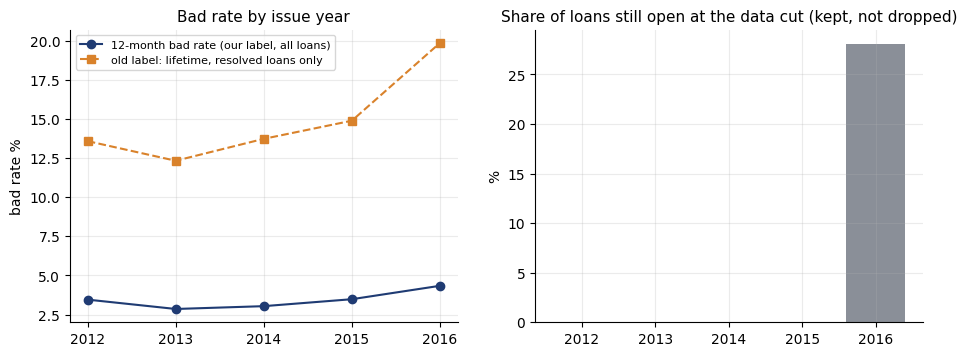

 issue_year  loans  A_bad_in_window_charged_off_lastpay_le_9  B_grey_zone_charged_off_lastpay_10_12  C_charged_off_after_window_lastpay_gt_12  D_late_or_grace_at_cut  E_current_at_cut  F_fully_paid  share_of_window_good_that_later_charged_off
       2012  43470                                      1502                                    726                                      3675                       0                 0         37567                                       0.1049
       2013 100422                                      2870                                   1373                                      8135                       0                 0         88044                                       0.0975
       2014 162570                                      4939                                   2631                                     14745                       0                 0        140255                                       0.1102
       2015 282934          

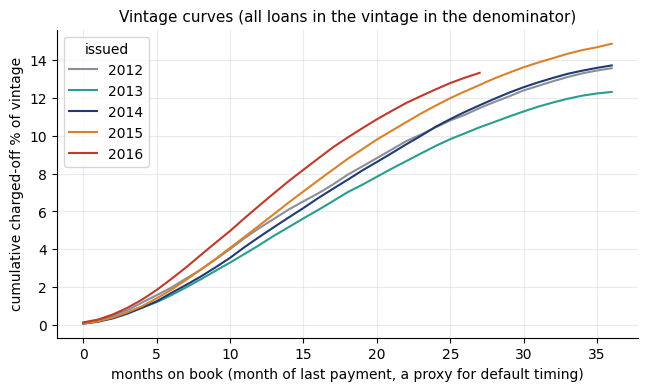

In [5]:
# ---- Outcome mix: 12-month label vs the old lifetime/resolved-only label, by vintage -------------------
st = pd.crosstab(base["year"], base["loan_status"])
bad_cols = [c for c in st.columns if c in L.BAD_STATUS]; good_cols = [c for c in st.columns if c in L.GOOD_STATUS]
vint = pd.DataFrame({"loans": st.sum(axis=1), "bad_12m": base.groupby("year")["y"].sum().astype(int),
                     "resolved_bad": st[bad_cols].sum(axis=1), "resolved_good": st[good_cols].sum(axis=1)})
vint["bad_rate_12m"] = vint["bad_12m"] / vint["loans"]
vint["open_at_cut"] = vint["loans"] - vint["resolved_bad"] - vint["resolved_good"]
vint["share_open_at_cut"] = vint["open_at_cut"] / vint["loans"]
vint["bad_rate_lifetime_resolved_only"] = vint["resolved_bad"] / (vint["resolved_bad"] + vint["resolved_good"])
vint["bad_rate_lifetime_open_as_good"] = vint["resolved_bad"] / vint["loans"]
vint = vint.reset_index().rename(columns={"year": "issue_year"})
save_csv(vint, "bad_rate_by_vintage.csv"); save_csv(st.reset_index(), "loan_status_by_year.csv")
print(vint.round(4).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(vint.issue_year, vint.bad_rate_12m * 100, "o-", color=NAVY, label="12-month bad rate (our label, all loans)")
ax[0].plot(vint.issue_year, vint.bad_rate_lifetime_resolved_only * 100, "s--", color=ORANGE, label="old label: lifetime, resolved loans only")
ax[0].set_ylabel("bad rate %"); ax[0].set_title("Bad rate by issue year"); ax[0].legend(fontsize=8); ax[0].set_xticks(vint.issue_year)
ax[1].bar(vint.issue_year, vint.share_open_at_cut * 100, color=GREY); ax[1].set_title("Share of loans still open at the data cut (kept, not dropped)")
ax[1].set_ylabel("%"); ax[1].set_xticks(vint.issue_year)
savefig(fig, "bad_rate_by_vintage.png", "The 12-month bad rate (navy) is measured on every loan over the same one-year window, so vintages are comparable. The old lifetime resolved-only label (orange) is distorted where many loans were still open at the data cut (right panel).")

# ---- Status-transition view (what the snapshot fields allow; NOT a monthly roll-rate matrix) --------------
bad_ls = base["loan_status"].isin(L.BAD_STATUS); mb = base["mob_last_pay"]
trans = pd.DataFrame({
    "A_bad_in_window_charged_off_lastpay_le_9": (bad_ls & (mb <= L.BAD_MAX_MOB)).groupby(base["year"]).sum(),
    "B_grey_zone_charged_off_lastpay_10_12": (bad_ls & (mb > L.BAD_MAX_MOB) & (mb <= 12)).groupby(base["year"]).sum(),
    "C_charged_off_after_window_lastpay_gt_12": (bad_ls & (mb > 12)).groupby(base["year"]).sum(),
    "D_late_or_grace_at_cut": base["loan_status"].isin(["In Grace Period", "Late (16-30 days)", "Late (31-120 days)"]).groupby(base["year"]).sum(),
    "E_current_at_cut": (base["loan_status"] == "Current").groupby(base["year"]).sum(),
    "F_fully_paid": base["loan_status"].isin(L.GOOD_STATUS).groupby(base["year"]).sum()}).astype(int)
trans.insert(0, "loans", trans.sum(axis=1))
trans["share_of_window_good_that_later_charged_off"] = (trans["B_grey_zone_charged_off_lastpay_10_12"] + trans["C_charged_off_after_window_lastpay_gt_12"]) / (trans["loans"] - trans["A_bad_in_window_charged_off_lastpay_le_9"])
trans = trans.reset_index().rename(columns={"year": "issue_year"}); save_csv(trans, "status_transition_by_vintage.csv")
print(trans.round(4).to_string(index=False))

# ---- Months-on-book curves (analysis only; last_pymnt_d is NEVER a model input) --------------
mob = ((base["last_pymnt_d"].dt.year - base["issue_d"].dt.year) * 12 + (base["last_pymnt_d"].dt.month - base["issue_d"].dt.month)).fillna(0).clip(0, 36)
is_bad = base["loan_status"].isin(L.BAD_STATUS)
rows = []
for yr in range(2012, 2017):
    m = base["year"] == yr
    horizon = min(36, (SNAPSHOT.year - yr) * 12 + SNAPSHOT.month - 12)     # months observable for the LAST month of that year
    for k in range(0, 37):
        if k <= horizon:
            rows.append({"issue_year": yr, "months_on_book": k, "cum_bad_share": float(((mob[m] <= k) & is_bad[m]).sum() / m.sum()), "fully_observed_to": horizon})
vc = pd.DataFrame(rows); save_csv(vc, "vintage_curves.csv")
fig, ax = plt.subplots(figsize=(7.5, 4))
for yr, c in zip(range(2012, 2017), [GREY, TEAL, NAVY, ORANGE, RED]):
    s = vc[vc.issue_year == yr]; ax.plot(s.months_on_book, s.cum_bad_share * 100, color=c, label=str(yr))
ax.set_xlabel("months on book (month of last payment, a proxy for default timing)"); ax.set_ylabel("cumulative charged-off % of vintage")
ax.set_title("Vintage curves (all loans in the vintage in the denominator)"); ax.legend(title="issued")
savefig(fig, "vintage_curves.png", "Each line is a year of lending. Newer vintages default faster and higher. 2016 is only fully observable for roughly two years, so its curve stops early.")

**Roll-rate note.** A true roll-rate matrix (current -> 30 -> 60 -> 90 DPD, month by month) needs monthly delinquency history, which the public LendingClub file does not
contain: it has one snapshot status and the last-payment month per loan. The status-transition table above is the closest the fields allow: how each vintage splits into bad-inside-window,
the grey zone (stopped paying in months 10-12), charged off after the window, still late/current at the cut, and paid. Its last column is the share of window-good loans that
still end up charged off later, i.e. the part of lifetime loss a 12-month PD does not see.

In [6]:
# ---- Features, time split, sampling ------------------------------------------------------------
D = D.sort_values("issue_d").reset_index(drop=True)
Xall = L.engineer(D)
yall = D["y"].astype(int).values
dev = D["year"].between(2013, 2015).values
oot = (D["year"] == 2016).values
months = D.loc[dev, "issue_d"]
cum = months.value_counts().sort_index().cumsum() / dev.sum()
CUT_MONTH = cum.index[np.argmax(cum.values >= 0.80)]
is_train = dev & (D["issue_d"] <= CUT_MONTH).values
is_valid = dev & (D["issue_d"] > CUT_MONTH).values

def strat_sample(idx_bool, cap, seed):
    idx = np.where(idx_bool)[0]
    if cap is None or len(idx) <= cap:
        return idx
    r = np.random.default_rng(seed)
    y_ = yall[idx]
    keep = np.concatenate([r.choice(idx[y_ == c], int(round(cap * (y_ == c).mean())), replace=False) for c in (0, 1)])
    return np.sort(keep)

n_train_full = int(is_train.sum())
tr_idx = strat_sample(is_train, CAPS["train"], SEED)
va_idx = strat_sample(is_valid, CAPS["valid"], SEED + 1)
oot_idx = strat_sample(oot, CAPS["oot"], SEED + 2)
Xtr, ytr = Xall.iloc[tr_idx], yall[tr_idx]
Xva, yva = Xall.iloc[va_idx], yall[va_idx]
split = pd.DataFrame([
    {"set": "train", "issue_window": f"{D.issue_d[tr_idx].min():%b-%Y} to {CUT_MONTH:%b-%Y}", "rows_before_sampling": n_train_full, "rows_used": len(tr_idx), "bad_rate": ytr.mean()},
    {"set": "validation", "issue_window": f"{D.issue_d[va_idx].min():%b-%Y} to {D.issue_d[va_idx].max():%b-%Y}", "rows_before_sampling": int(is_valid.sum()), "rows_used": len(va_idx), "bad_rate": yva.mean()},
    {"set": "OOT test", "issue_window": "Jan-2016 to Dec-2016", "rows_before_sampling": int(oot.sum()), "rows_used": len(oot_idx), "bad_rate": yall[oot_idx].mean()}])
save_csv(split, "split_summary.csv")
# rows dropped per split because of the label definition (the old lifetime label dropped every loan not Fully Paid / Charged Off)
_resolved = D["loan_status"].isin(L.BAD_STATUS + L.GOOD_STATUS).values
drop_tab = pd.DataFrame([{"set": nm, "loans_in_split": int(m.sum()), "dropped_for_unresolved_status_now": 0,
                          "would_have_been_dropped_by_old_lifetime_label": int((m & ~_resolved).sum()),
                          "old_label_drop_share": float((m & ~_resolved).sum() / m.sum())}
                         for nm, m in [("train", is_train), ("validation", is_valid), ("OOT test", oot)]])
save_csv(drop_tab, "dropped_by_split.csv"); print(drop_tab.to_string(index=False))
SAMPLING_NOTE = (f"Train was stratified-downsampled from {n_train_full:,} to {len(tr_idx):,} rows" if len(tr_idx) < n_train_full else "No downsampling needed for train")
print(SAMPLING_NOTE); tick("split ready")
split

       set  loans_in_split  dropped_for_unresolved_status_now  would_have_been_dropped_by_old_lifetime_label  old_label_drop_share
     train          438588                                  0                                              4              0.000009
validation          107338                                  0                                            143              0.001332
  OOT test          318277                                  0                                          89464              0.281088
Train was stratified-downsampled from 438,588 to 400,000 rows
[   1.3 min] split ready


,set,issue_window,rows_before_sampling,rows_used,bad_rate
0,train,Jan-2013 to Aug-2015,438588,400000,0.031275
1,validation,Sep-2015 to Dec-2015,107338,107338,0.036744
2,OOT test,Jan-2016 to Dec-2016,318277,318277,0.043384


### Data quality: missing values, sentinel codes, outlier caps

**Banker's note.** Missingness here is mostly *structural* (e.g. "months since last delinquency" is blank when there never was
a delinquency), so it is information, not noise: WoE binning gives the missing group its own bin and the logistic
models add a missing-flag. Sentinels are set to missing (`dti` of -1 or 999, `annual_inc` of 0). Extreme values are
winsorised at the 0.5th/99.5th percentile learned on **train only**.

**Plain-English note.** Blank cells often mean "nothing bad happened", so we keep them as a signal. Absurd entries (an
income of zero, a debt ratio of 999) are treated as unknown rather than believed.

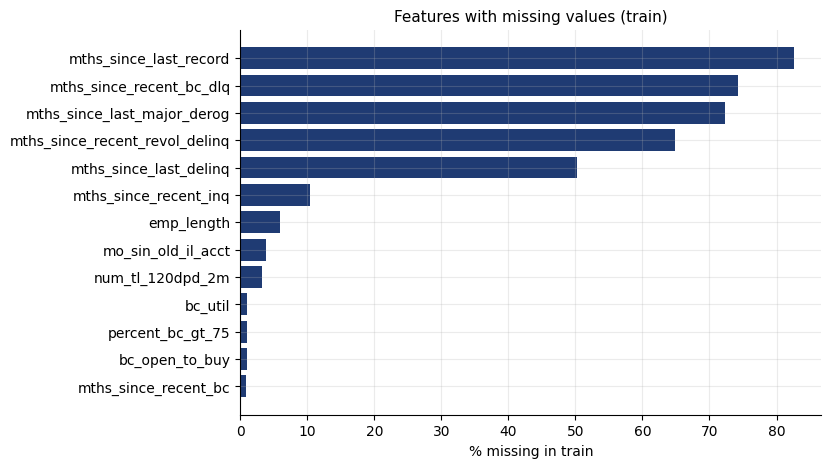

                                rule  rows_affected_train
dti < 0 or dti >= 999 set to missing                    0
      annual_inc <= 0 set to missing                    0


,feature,p0.5,median,p99.5,max,share_beyond_caps
21,total_rev_hi_lim,2000.000,21600.0,186700.130,9999999.0,0.009513
55,tot_hi_cred_lim,5900.000,92096.0,879443.350,9999999.0,0.009987
19,tot_coll_amt,0.000,0.0,9120.020,9152545.0,0.005000
2,annual_inc,15000.000,60000.0,300000.000,8900060.0,0.009647
20,tot_cur_bal,2130.000,64067.0,777302.095,4772549.0,0.009997
56,total_bal_ex_mort,1612.995,33644.0,273536.050,2921551.0,0.010000


In [7]:
miss = pd.DataFrame({"feature": Xtr.columns,
                     "label": [L.LABELS[c] for c in Xtr.columns],
                     "missing_train": Xtr.isna().mean().values,
                     "missing_valid": Xva.isna().mean().values,
                     "missing_oot": Xall.iloc[oot_idx].isna().mean().values}).sort_values("missing_train", ascending=False)
save_csv(miss, "missingness.csv")
top = miss[miss.missing_train > 0.005].head(20)
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.barh(top.feature[::-1], top.missing_train[::-1] * 100, color=NAVY); ax.set_xlabel("% missing in train")
ax.set_title("Features with missing values (train)")
savefig(fig, "missingness.png", "Most blanks are 'never happened' cases (no delinquency, no public record). We keep them as their own category rather than guessing a value.")

caps = []
for c in L.NUMERIC_FEATURES:
    x = Xtr[c]
    caps.append({"feature": c, "p0.5": x.quantile(.005), "median": x.median(), "p99.5": x.quantile(.995), "max": x.max(),
                 "share_beyond_caps": float(((x < x.quantile(.005)) | (x > x.quantile(.995))).mean())})
caps = pd.DataFrame(caps); save_csv(caps, "outlier_caps.csv")
sent = pd.DataFrame({"rule": ["dti < 0 or dti >= 999 set to missing", "annual_inc <= 0 set to missing"],
                     "rows_affected_train": [int(((D.loc[Xtr.index, 'dti'] < 0) | (D.loc[Xtr.index, 'dti'] >= 999)).sum()),
                                             int((D.loc[Xtr.index, 'annual_inc'] <= 0).sum())]})
save_csv(sent, "sentinel_rules.csv"); print(sent.to_string(index=False))
caps.sort_values("max", ascending=False).head(6)

## Stage 3 - Univariate analysis: fine classing, coarse classing, WoE and IV

**What.** For each feature: (a) *fine classing* into ~20 equal-sized bins to see the raw shape and IV; (b) *coarse classing*
with `optbinning` into at most 6 bins with a **monotone** bad-rate trend (so each variable tells one clean story);
(c) compute Weight of Evidence per bin, WoE = ln(share of goods / share of bads), and Information Value
IV = sum over bins of (share of goods - share of bads) x WoE. All bins are learned on **train only**.

**Rules.** IV < 0.02: useless, dropped. 0.02-0.1 weak, 0.1-0.3 medium, 0.3-0.5 strong. IV > 0.5: *suspiciously strong*,
flagged as a possible leakage and not used automatically.

**Banker's note.** WoE coding makes the logistic model additive and readable as a points table, handles missing values and
outliers without imputation, and linearises the log-odds. Monotonic bins are required so every point-table row can be
explained to a credit committee and a regulator.

**Plain-English note.** We group each detail (e.g. income) into a few bands, check how much riskier or safer each band is,
and score each detail by how well it separates people who repay from those who don't.

In [8]:
from optbinning import OptimalBinning
woe_fine, woe = L.WoEMap(), L.WoEMap()
ytr_s = pd.Series(ytr)
bin_idx = np.random.default_rng(SEED).choice(len(Xtr), min(len(Xtr), 150_000 if not FAST else 40_000), replace=False)
iv_rows, t_bin = [], time.time()
for c in L.ALL_FEATURES:
    is_cat = c in L.CATEGORICAL_FEATURES
    x_full = Xtr[c].astype("object").values if is_cat else Xtr[c].values.astype(float)
    # (a) fine classing
    if is_cat:
        levels = [[str(v)] for v in pd.Series(x_full).dropna().astype(str).unique()]
        sf = woe_fine.fit_var(c, x_full, ytr, "cat", groups=levels)
    else:
        q = np.unique(np.nanquantile(x_full, np.linspace(0.05, 0.95, 19)))
        q = q[q > np.nanmin(x_full)]
        sf = woe_fine.fit_var(c, x_full, ytr, "num", splits=q)
    # (b) coarse classing: optbinning proposes monotone cut points on a sample, WoE/IV recomputed on all train
    try:
        ob = OptimalBinning(name=c, dtype="categorical" if is_cat else "numerical", solver="cp",
                            monotonic_trend=None if is_cat else "auto", max_n_bins=6, min_bin_size=0.05,
                            max_n_prebins=20, cat_cutoff=0.01 if is_cat else None, time_limit=20)
        ob.fit(x_full[bin_idx], ytr[bin_idx])
        spl = ob.splits
        ok = ob.status in ("OPTIMAL", "FEASIBLE") and len(spl) > 0
    except Exception as e:
        ok, spl = False, []
    if not ok:
        spl = [[str(v)] for v in pd.Series(x_full).dropna().astype(str).unique()] if is_cat else np.unique(np.nanquantile(x_full, [1/3, 2/3]))
    sc = woe.fit_var(c, x_full, ytr, "cat" if is_cat else "num",
                     **({"groups": [list(g) for g in spl]} if is_cat else {"splits": list(spl)}))
    iv_rows.append({"feature": c, "label": L.LABELS[c], "group": L.GROUPS[c], "iv_fine": sf["iv"], "iv_coarse": sc["iv"],
                    "n_bins": len(sc["woe"]), "has_missing_bin": any(r["bin_index"] == -1 for r in sc["table"]),
                    "monotone": L.monotone_flag(sc["table"]) if not is_cat else True,
                    "optbinning_ok": bool(ok)})
iv = pd.DataFrame(iv_rows).sort_values("iv_coarse", ascending=False).reset_index(drop=True)
iv["strength"] = pd.cut(iv.iv_coarse, [-1, .02, .1, .3, .5, 99], labels=["useless (<0.02)", "weak", "medium", "strong", "SUSPICIOUS (>0.5)"]).astype(str)
iv["decision"] = np.where(iv.iv_coarse < 0.02, "drop: IV < 0.02", np.where(iv.iv_coarse > 0.5, "flag: IV > 0.5 leakage suspect", "keep"))
save_csv(iv, "iv_table.csv"); save_csv(woe.bins_table(), "woe_bins.csv")
tick(f"binning done in {(time.time() - t_bin) / 60:.1f} min; {int((iv.decision == 'keep').sum())} of {len(iv)} features pass IV >= 0.02")
iv.head(15)[["feature", "group", "iv_fine", "iv_coarse", "n_bins", "monotone", "strength", "decision"]]

[   1.5 min] binning done in 0.2 min; 27 of 62 features pass IV >= 0.02


,feature,group,iv_fine,iv_coarse,n_bins,monotone,strength,decision
0,fico,Bureau,0.118068,0.111547,6,True,medium,keep
1,acc_open_past_24mths,Bureau,0.091745,0.091068,6,True,weak,keep
2,num_tl_op_past_12m,Bureau,0.083978,0.083978,6,True,weak,keep
3,annual_inc,Applicant,0.075853,0.073893,6,True,weak,keep
4,dti,Applicant,0.074826,0.073416,6,True,weak,keep
5,bc_open_to_buy,Bureau,0.072118,0.071832,6,True,weak,keep
6,mths_since_recent_inq,Bureau,0.068492,0.067709,6,True,weak,keep
7,inq_last_6mths,Bureau,0.066940,0.066940,4,True,weak,keep
8,tot_hi_cred_lim,Bureau,0.065126,0.063568,6,True,weak,keep
9,mo_sin_rcnt_tl,Bureau,0.064130,0.061457,6,True,weak,keep


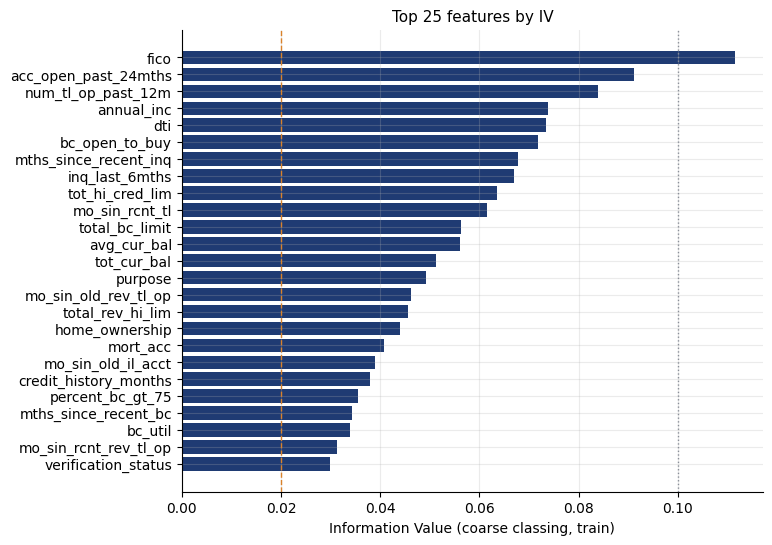

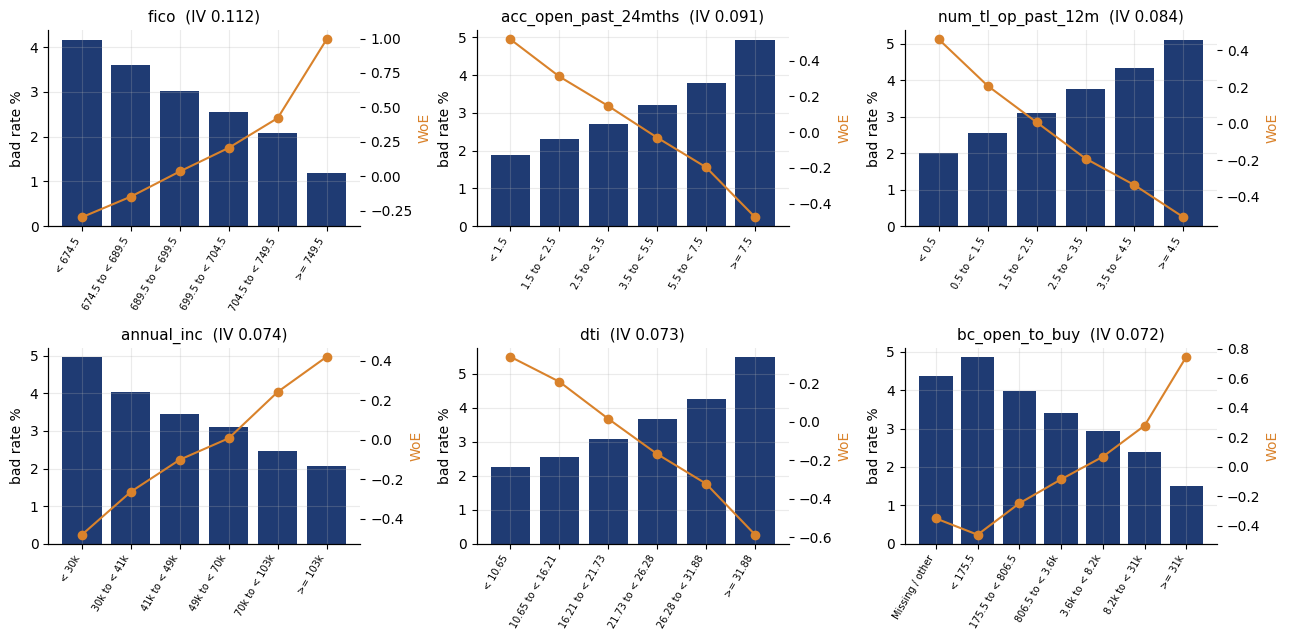

In [9]:
top = iv.head(25)
fig, ax = plt.subplots(figsize=(7.5, 6))
cols = [NAVY if d == "keep" else GREY for d in top.decision]
ax.barh(top.feature[::-1], top.iv_coarse[::-1], color=cols[::-1])
ax.axvline(0.02, ls="--", color=ORANGE, lw=1); ax.axvline(0.1, ls=":", color=GREY, lw=1)
ax.set_xlabel("Information Value (coarse classing, train)"); ax.set_title("Top 25 features by IV")
savefig(fig, "iv_bar.png", "Longer bar = better at separating good from bad borrowers. FICO and utilisation-type variables lead; nothing exceeds 0.5, so no variable looks like leakage.")

show = [f for f in iv.feature.head(6)]
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, f in zip(axes.ravel(), show):
    t = woe.bins_table(); t = t[t.variable == f]
    ax.bar(range(len(t)), t.bad_rate * 100, color=NAVY)
    ax.set_xticks(range(len(t))); ax.set_xticklabels([b[:18] for b in t.bin], rotation=60, ha="right", fontsize=7)
    ax2 = ax.twinx(); ax2.plot(range(len(t)), t.woe, "o-", color=ORANGE); ax2.grid(False); ax2.set_ylabel("WoE", color=ORANGE)
    ax.set_title(f"{f}  (IV {iv.set_index('feature').loc[f, 'iv_coarse']:.3f})"); ax.set_ylabel("bad rate %")
fig.tight_layout()
savefig(fig, "woe_bins_top6.png", "Bars are the bad rate in each band, the orange line is its WoE. Bands are monotone: as the variable moves, risk moves one way only.")

## Stage 4 - Multicollinearity: correlation, VIF, condition index, sign check

**What.** Among features that passed IV, (1) list pairs with |correlation| > 0.7 (on the WoE-coded matrix, i.e. the actual
model inputs) and keep the higher-IV member; (2) iteratively drop the feature with the largest Variance Inflation
Factor until all VIF < 5; (3) report the condition index; (4) later check every coefficient sign against business
expectation.

**Banker's note.** Collinearity does not hurt prediction much but it makes coefficients unstable and unexplainable
(a "sign flip" on income because loan-to-income is also in the model). VIF is computed from the inverse correlation
matrix, which is algebraically identical to regressing each variable on the others; the final set is cross-checked
with `statsmodels.variance_inflation_factor`.

**Plain-English note.** If two inputs say almost the same thing, the model can't tell which deserves the credit.
We keep the better one so each remaining variable tells its own story.

9 pairs with |r|>0.7; dropped 7 features (lower IV of each pair)
[   1.7 min] after corr: 20 | after VIF<5: 20 | condition index 3.6


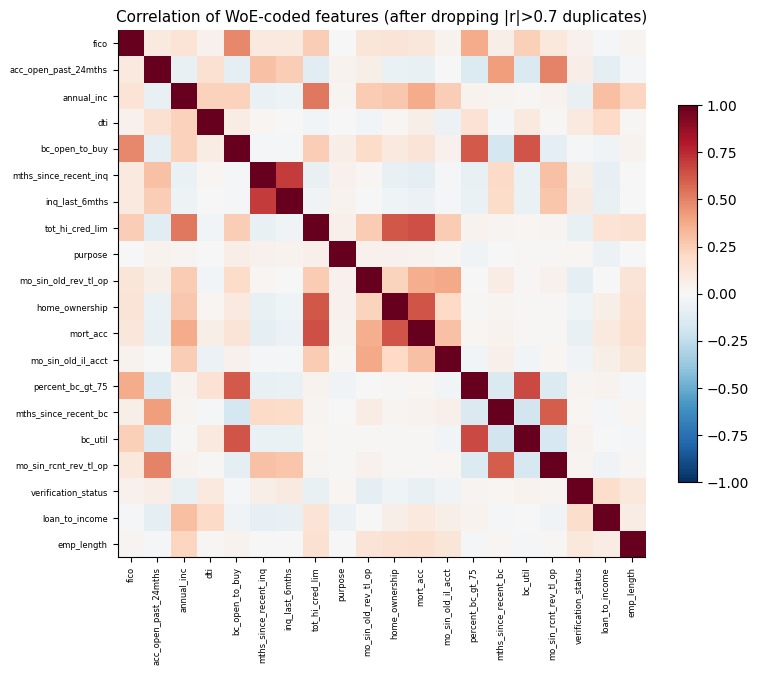

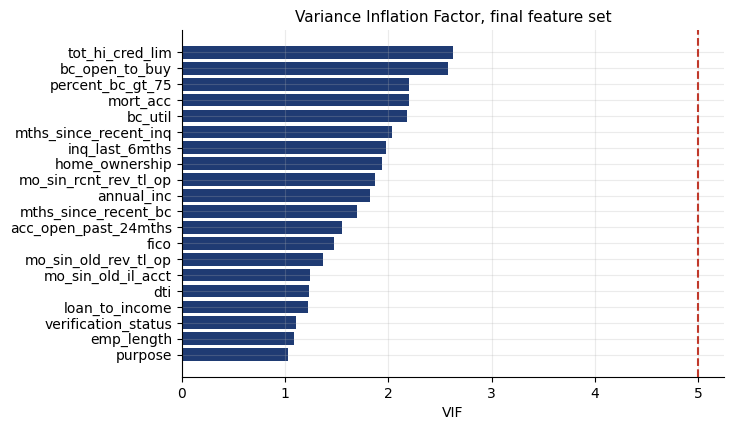

,feature,vif,vif_statsmodels_check_60k_rows
7,tot_hi_cred_lim,2.629883,2.784156
4,bc_open_to_buy,2.575086,2.659359
13,percent_bc_gt_75,2.197877,2.217010
11,mort_acc,2.197205,2.408859
15,bc_util,2.180924,2.200541
5,mths_since_recent_inq,2.039678,2.611424
6,inq_last_6mths,1.979099,2.535474
10,home_ownership,1.936301,2.131587


In [10]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
keep0 = iv.loc[iv.decision == "keep", "feature"].tolist()
ivmap = iv.set_index("feature").iv_coarse
W = woe.transform(Xtr, keep0)
C = W.corr()
pairs = [(a, b, C.loc[a, b]) for i, a in enumerate(keep0) for b in keep0[i + 1:] if abs(C.loc[a, b]) > 0.7]
pairs = pd.DataFrame(pairs, columns=["var_a", "var_b", "corr"])
pairs["drop"] = [a if ivmap[a] < ivmap[b] else b for a, b, _ in pairs.itertuples(index=False, name=None)] if len(pairs) else []
pairs["keep"] = [b if d == a else a for a, b, d in pairs[["var_a", "var_b", "drop"]].itertuples(index=False, name=None)] if len(pairs) else []
save_csv(pairs, "corr_pairs_gt_0_7.csv")
# greedy: process strongest pairs first, skip pairs whose member is already gone
dropped_corr, alive = [], set(keep0)
for a, b, r in sorted(pairs[["var_a", "var_b", "corr"]].itertuples(index=False, name=None), key=lambda t: -abs(t[2])):
    if a in alive and b in alive:
        d = a if ivmap[a] < ivmap[b] else b
        alive.discard(d); dropped_corr.append((d, a if d == b else b, r))
print(f"{len(pairs)} pairs with |r|>0.7; dropped {len(dropped_corr)} features (lower IV of each pair)")
keep1 = [v for v in keep0 if v in alive]

def vif_series(Wm):
    Cm = np.corrcoef(Wm.values, rowvar=False)
    return pd.Series(np.diag(np.linalg.inv(Cm)), index=Wm.columns)

vif_log, cur = [], list(keep1)
while True:
    vs = vif_series(W[cur])
    worst = vs.idxmax()
    if vs.max() <= 5 or len(cur) <= 3:
        break
    vif_log.append({"iteration": len(vif_log) + 1, "dropped": worst, "vif_at_drop": vs.max(), "iv": ivmap[worst]})
    cur.remove(worst)
keep2 = cur
vif_final = vif_series(W[keep2]).rename("vif").reset_index().rename(columns={"index": "feature"}).sort_values("vif", ascending=False)
chk = [variance_inflation_factor(sm.add_constant(W[keep2].iloc[:60000]).values, i + 1) for i in range(len(keep2))]
vif_final["vif_statsmodels_check_60k_rows"] = pd.Series(chk, index=keep2).reindex(vif_final.feature).values
save_csv(vif_final, "vif_final.csv"); save_csv(pd.DataFrame(vif_log, columns=["iteration", "dropped", "vif_at_drop", "iv"]), "vif_iterations.csv")
ev = np.linalg.eigvalsh(np.corrcoef(W[keep2].values, rowvar=False))
cond = float(np.sqrt(ev.max() / ev.min()))
save_json({"condition_index": cond, "n_features_after_corr": len(keep1), "n_features_after_vif": len(keep2),
           "dropped_by_corr": [(d, k, float(r)) for d, k, r in dropped_corr], "dropped_by_vif": [r["dropped"] for r in vif_log]}, "multicollinearity.json")
Cs = W[keep1].corr(); save_csv(Cs.reset_index().rename(columns={"index": "feature"}), "corr_matrix_woe.csv")
tick(f"after corr: {len(keep1)} | after VIF<5: {len(keep2)} | condition index {cond:.1f}")

fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(Cs.values, cmap="RdBu_r", vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(len(Cs))); ax.set_xticklabels(Cs.columns, rotation=90, fontsize=6); ax.set_yticks(range(len(Cs))); ax.set_yticklabels(Cs.columns, fontsize=6)
fig.colorbar(im, shrink=.7); ax.set_title("Correlation of WoE-coded features (after dropping |r|>0.7 duplicates)")
savefig(fig, "corr_heatmap.png", "Red/blue squares mark features that move together. After pruning, no pair exceeds 0.7, so each variable adds distinct information.")
fig, ax = plt.subplots(figsize=(7, 4.5)); v = vif_final.sort_values("vif")
ax.barh(v.feature, v.vif, color=NAVY); ax.axvline(5, ls="--", color=RED); ax.set_xlabel("VIF"); ax.set_title("Variance Inflation Factor, final feature set")
savefig(fig, "vif_bar.png", "VIF measures how well other inputs can predict a given input. Everything is under the red line (5), so coefficients will be stable.")
vif_final.head(8)

## Stage 5 - The logistic ladder

Five rungs, all fitted on **train**, tuned only with stratified 5-fold CV on train, compared on **validation**:

1. **Plain logistic regression** (statsmodels, no penalty): p-values, odds ratios, convergence check.
2. **L2 (ridge)**, 3. **L1 (lasso)**, 4. **ElasticNet**: scikit-learn, regularisation strength (and L1 share) tuned by CV AUC.
5. **WoE scorecard**: logistic regression on WoE-coded inputs, converted to points (PDO = 20, 600 points at 50:1 good:bad odds).

Plus: the class-imbalance comparison (none vs `class_weight` vs SMOTE *inside* the CV loop), Hosmer-Lemeshow calibration test,
a calibration curve and coefficient stability across folds.

**Banker's note.** Logistic regression remains the regulatory default because every driver has a sign, a size and a p-value.
Regularisation trades a little in-sample fit for stability; ElasticNet is the sensible compromise when features are correlated.
The scorecard form is what a credit committee signs off: a points table anyone can recompute by hand.

**Plain-English note.** We start with the simplest, most explainable model and add safeguards one at a time. The scorecard
turns the final model into a table of points, like a quiz where a higher score means a safer borrower.

{'converged': True, 'iterations': 8, 'llf': -52834.88354786996, 'pseudo_r2': 0.05073373719750518, 'aic': 105737.76709573992, 'nobs': 400000}


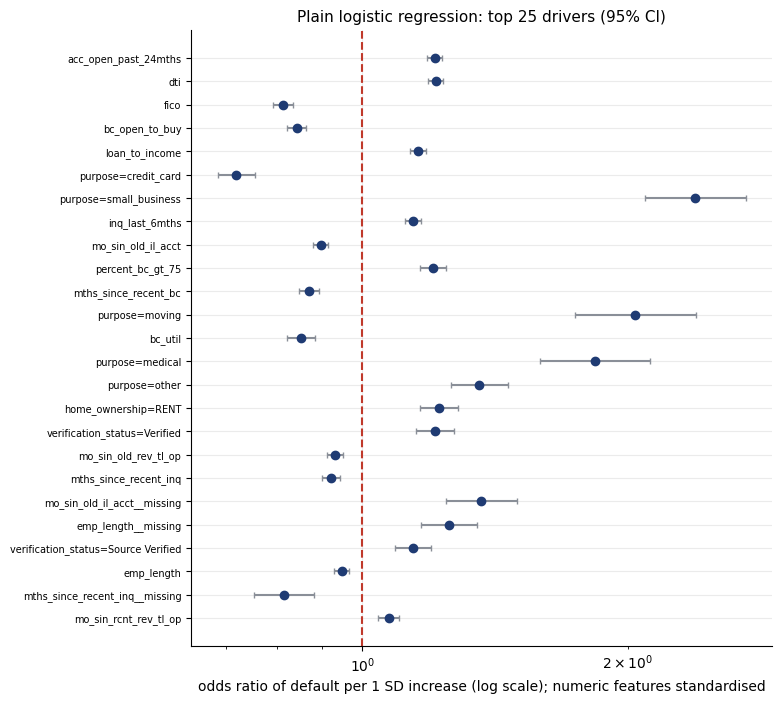

,feature,coef,p_value,odds_ratio
2,acc_open_past_24mths,0.189428,1.561975e-78,1.208558
4,dti,0.191470,7.901348e-76,1.211029
1,fico,-0.207798,3.527337e-55,0.812371
5,bc_open_to_buy,-0.171224,3.882586e-45,0.842633
18,loan_to_income,0.146470,3.544728e-44,1.157740
21,purpose=credit_card,-0.329062,4.121743e-40,0.719599
27,purpose=small_business,0.869689,5.766460e-38,2.386170
8,inq_last_6mths,0.132182,3.091683e-36,1.141316


In [11]:
# ---- Rung 1: plain logistic regression (statsmodels) on the VIF-pruned raw features --------------
sel_vars = keep2
num_sel = [v for v in sel_vars if v in L.NUMERIC_FEATURES]; cat_sel = [v for v in sel_vars if v in L.CATEGORICAL_FEATURES]
prep = L.RawPrep(num_sel, cat_sel).fit(Xtr)
A_tr, A_va = prep.transform(Xtr), prep.transform(Xva)
names_lr = prep.names()
tune_idx = np.random.default_rng(SEED).choice(len(Xtr), min(len(Xtr), CAPS["tune"]), replace=False)

sm_fit = sm.Logit(ytr, sm.add_constant(A_tr, prepend=True)).fit(method="newton", maxiter=100, disp=0)
conv = {"converged": bool(sm_fit.mle_retvals["converged"]), "iterations": int(sm_fit.mle_retvals.get("iterations", -1)), "llf": float(sm_fit.llf), "pseudo_r2": float(sm_fit.prsquared), "aic": float(sm_fit.aic), "nobs": int(sm_fit.nobs)}
ci = sm_fit.conf_int()
plain = pd.DataFrame({"feature": ["const"] + names_lr, "coef": sm_fit.params, "std_err": sm_fit.bse, "z": sm_fit.tvalues, "p_value": sm_fit.pvalues,
                      "odds_ratio": np.exp(sm_fit.params), "or_ci_low": np.exp(ci[:, 0]), "or_ci_high": np.exp(ci[:, 1])})
save_csv(plain, "statsmodels_logit_raw.csv"); save_json(conv, "statsmodels_convergence.json")
print(conv)
raw_feats_pd = plain[plain.feature != "const"].copy()
fig, ax = plt.subplots(figsize=(7.5, 8))
rf = raw_feats_pd.assign(absz=lambda d: d.z.abs()).sort_values("absz", ascending=False).head(25).iloc[::-1]
ax.errorbar(rf.odds_ratio, range(len(rf)), xerr=[rf.odds_ratio - rf.or_ci_low, rf.or_ci_high - rf.odds_ratio], fmt="o", color=NAVY, ecolor=GREY, capsize=2)
ax.axvline(1, color=RED, ls="--"); ax.set_yticks(range(len(rf))); ax.set_yticklabels(rf.feature, fontsize=7); ax.set_xscale("log")
ax.set_xlabel("odds ratio of default per 1 SD increase (log scale); numeric features standardised"); ax.set_title("Plain logistic regression: top 25 drivers (95% CI)")
savefig(fig, "odds_ratio_forest.png", "Right of the red line = raises the odds of default, left = lowers them. Intervals that avoid the line are statistically clear effects.")
raw_feats_pd.assign(absz=lambda d: d.z.abs()).sort_values("absz", ascending=False).head(8)[["feature", "coef", "p_value", "odds_ratio"]]

[   1.9 min] l2: best {'C': 1.0}, cv AUC 0.6863, 0.1 min
[   2.0 min] l1: best {'C': 0.1}, cv AUC 0.6855, 0.1 min
[   2.4 min] elasticnet: best {'C': 0.3, 'l1_ratio': 0.3}, cv AUC 0.6865, 0.4 min
features zeroed by L1: 1 | by ElasticNet: 0 of 33


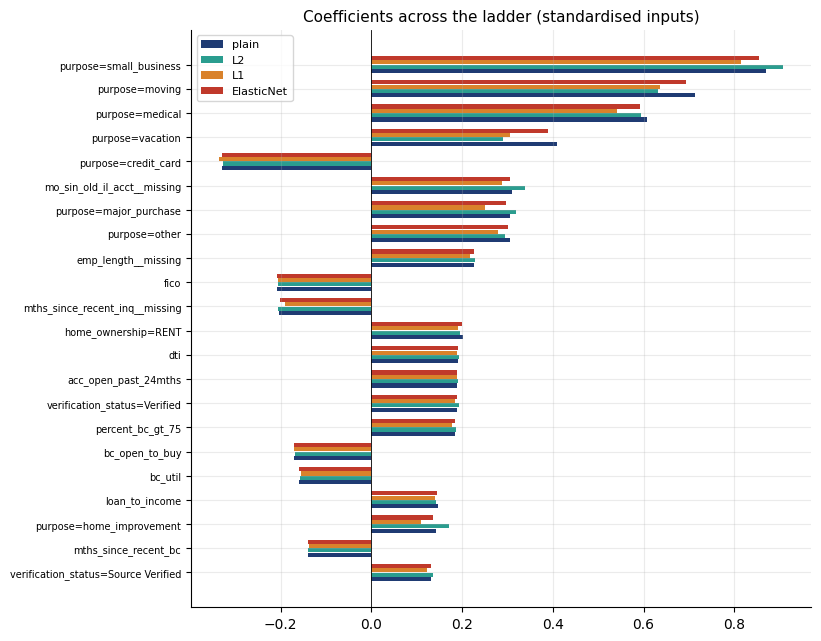

In [12]:
# ---- Rungs 2-4: L2 / L1 / ElasticNet tuned by stratified 5-fold CV on a train sub-sample --------
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
A_t, y_t = A_tr[tune_idx], ytr[tune_idx]
grids = {
 "l2": (LogisticRegression(penalty="l2", solver="lbfgs", max_iter=300), {"C": [0.001, 0.01, 0.1, 1.0]}),
 "l1": (LogisticRegression(penalty="l1", solver="liblinear", max_iter=300), {"C": [0.001, 0.003, 0.01, 0.1]}),
 "elasticnet": (LogisticRegression(penalty="elasticnet", solver="saga", max_iter=300, tol=1e-3),
                {"C": [0.003, 0.03, 0.3], "l1_ratio": [0.3, 0.7]}),
}
lr_models, lr_cv = {}, []
for k, (est, g) in grids.items():
    t = time.time()
    gs = GridSearchCV(est, g, cv=skf, scoring="roc_auc", n_jobs=-1 if k != "elasticnet" else 4, refit=False).fit(A_t, y_t)
    best = gs.cv_results_["params"][int(np.argmax(gs.cv_results_["mean_test_score"]))]
    for p, m, s in zip(gs.cv_results_["params"], gs.cv_results_["mean_test_score"], gs.cv_results_["std_test_score"]):
        lr_cv.append({"model": k, "params": json.dumps(p), "cv_auc_mean": m, "cv_auc_std": s, "best": p == best})
    final = est.set_params(**best).fit(A_tr, ytr)         # refit on the FULL train sample with the chosen setting
    lr_models[k] = final
    tick(f"{k}: best {best}, cv AUC {max(gs.cv_results_['mean_test_score']):.4f}, {(time.time() - t) / 60:.1f} min")
save_csv(pd.DataFrame(lr_cv), "lr_ladder_cv.csv")
best_en = json.loads([r for r in lr_cv if r["model"] == "elasticnet" and r["best"]][0]["params"])
coef_tab = pd.DataFrame({"feature": names_lr, "plain": sm_fit.params[1:], **{k: m.coef_[0] for k, m in lr_models.items()}})
coef_tab["l1_zeroed"] = coef_tab["l1"] == 0; coef_tab["en_zeroed"] = coef_tab["elasticnet"] == 0
save_csv(coef_tab, "ladder_coefficients.csv")
print("features zeroed by L1:", int(coef_tab.l1_zeroed.sum()), "| by ElasticNet:", int(coef_tab.en_zeroed.sum()), "of", len(coef_tab))
fig, ax = plt.subplots(figsize=(8, 7.5))
ct = coef_tab.assign(a=lambda d: d.plain.abs()).sort_values("a", ascending=False).head(22).iloc[::-1]
yy = np.arange(len(ct))
for off, col, nm, c in [(-.27, "plain", "plain", NAVY), (-.09, "l2", "L2", TEAL), (.09, "l1", "L1", ORANGE), (.27, "elasticnet", "ElasticNet", RED)]:
    ax.barh(yy + off, ct[col], height=.17, label=nm, color=c)
ax.set_yticks(yy); ax.set_yticklabels(ct.feature, fontsize=7); ax.axvline(0, color="k", lw=.6); ax.legend(fontsize=8)
ax.set_title("Coefficients across the ladder (standardised inputs)")
savefig(fig, "ladder_coefficients.png", "Plain coefficients are the largest; ridge shrinks them, lasso and ElasticNet push weak ones to exactly zero. Strong drivers keep their sign on every rung.")

             strategy  cv_auc  cv_auc_std  cv_brier
                 none  0.6842      0.0152    0.0295
class_weight=balanced  0.6846      0.0153    0.2238
    SMOTE (inside CV)  0.6772      0.0144    0.2217


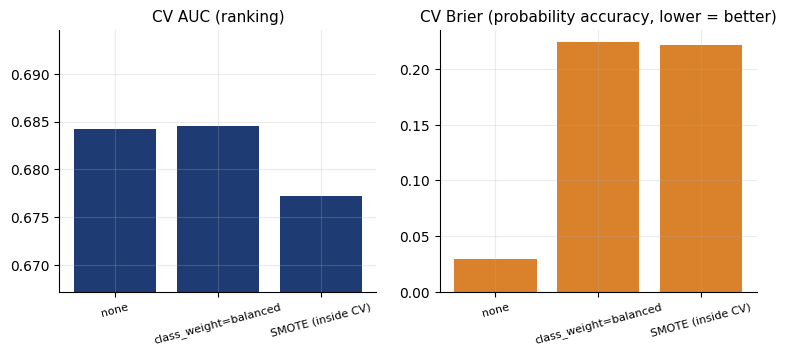

In [13]:
# ---- Imbalance: none vs class_weight vs SMOTE (SMOTE inside each CV fold), AUC and Brier -----------
res = []
sm_idx = np.random.default_rng(SEED + 7).choice(len(Xtr), min(len(Xtr), CAPS["smote"]), replace=False)
A_s, y_s = A_tr[sm_idx], ytr[sm_idx]
bestC = json.loads([r for r in lr_cv if r["model"] == "l2" and r["best"]][0]["params"])["C"]
strategies = {"none": LogisticRegression(C=bestC, max_iter=300), "class_weight=balanced": LogisticRegression(C=bestC, max_iter=300, class_weight="balanced")}
try:
    from imblearn.over_sampling import SMOTE
    from imblearn.pipeline import Pipeline as IPipe
    strategies["SMOTE (inside CV)"] = IPipe([("smote", SMOTE(random_state=SEED)), ("lr", LogisticRegression(C=bestC, max_iter=300))])
except Exception as e:
    print("imblearn unavailable, SMOTE skipped:", repr(e)[:100])
for nm, est in strategies.items():
    cvr = cross_validate(est, A_s, y_s, cv=skf, scoring={"auc": "roc_auc", "brier": "neg_brier_score"}, n_jobs=1)
    res.append({"strategy": nm, "cv_auc": cvr["test_auc"].mean(), "cv_auc_std": cvr["test_auc"].std(), "cv_brier": -cvr["test_brier"].mean()})
imb = pd.DataFrame(res); save_csv(imb, "imbalance_cv.csv"); print(imb.round(4).to_string(index=False))
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
ax[0].bar(imb.strategy, imb.cv_auc, color=NAVY); ax[0].set_ylim(imb.cv_auc.min() - .01, imb.cv_auc.max() + .01); ax[0].set_title("CV AUC (ranking)")
ax[1].bar(imb.strategy, imb.cv_brier, color=ORANGE); ax[1].set_title("CV Brier (probability accuracy, lower = better)")
for a in ax: a.tick_params(axis="x", labelrotation=15, labelsize=8)
savefig(fig, "imbalance_comparison.png", "Rebalancing does not improve ranking (AUC) but it distorts the probabilities (worse Brier). A PD model needs well-calibrated probabilities, so we keep the natural class mix.")

In [14]:
# ---- Rung 5: WoE scorecard = logistic on WoE inputs, sign-pruned, converted to points -------------
Wtr = woe.transform(Xtr, keep2); Wva = woe.transform(Xva, keep2)
cur = list(keep2)
while True:
    fit = sm.Logit(ytr, sm.add_constant(Wtr[cur])).fit(method="newton", maxiter=100, disp=0)
    pos = [v for v in cur if fit.params[v] > 0]                       # WoE = ln(good/bad): a sensible coefficient is NEGATIVE
    if pos:
        worst = max(pos, key=lambda v: fit.params[v]); cur.remove(worst); print("dropped (wrong sign):", worst); continue
    insig = [v for v in cur if fit.pvalues[v] > 0.01]
    if insig:
        worst = max(insig, key=lambda v: fit.pvalues[v]); cur.remove(worst); print("dropped (p>0.01):", worst); continue
    break
sc_vars = cur
sc = L.Scorecard(woe, sc_vars, {v: float(fit.params[v]) for v in sc_vars}, float(fit.params["const"]))
sc_tab = pd.DataFrame({"feature": ["const"] + sc_vars, "coef": fit.params.values, "std_err": fit.bse.values, "p_value": fit.pvalues.values,
                       "odds_ratio_per_unit_woe": np.exp(fit.params.values), "iv": [np.nan] + [ivmap[v] for v in sc_vars]})
save_csv(sc_tab, "scorecard_logit.csv")
save_json({"converged": bool(fit.mle_retvals["converged"]), "pseudo_r2": float(fit.prsquared), "variables": sc_vars, "n_variables": len(sc_vars),
           "pdo": L.PDO, "base_score": L.BASE_SCORE, "base_odds_good_to_bad": L.BASE_ODDS, "factor": L.FACTOR, "offset": L.OFFSET}, "scorecard_meta.json")
pts = sc.points_table(); save_csv(pts, "points_table.csv")
chk = np.abs(sc.score(Xva) - (L.OFFSET - L.FACTOR * L.logit(sc.raw_pd(Xva)))).max()
tick(f"scorecard: {len(sc_vars)} variables, {len(pts)} point rows; max |score - formula| = {chk:.2e}")
pts.groupby("variable").points.agg(["min", "max"]).assign(range=lambda d: d["max"] - d["min"]).sort_values("range", ascending=False).head(8)

dropped (wrong sign): mo_sin_rcnt_rev_tl_op
dropped (wrong sign): mort_acc
[   2.8 min] scorecard: 18 variables, 106 point rows; max |score - formula| = 1.14e-13


,min,max,range
variable,,,
purpose,-28.188933,41.875559,70.064492
home_ownership,7.540382,35.147196,27.606815
acc_open_past_24mths,22.489009,43.594514,21.105504
fico,28.530526,46.052994,17.522468
dti,21.765387,38.787470,17.022083
bc_util,24.253849,36.617690,12.363840
inq_last_6mths,24.666224,35.681540,11.015317
mths_since_recent_inq,27.695475,38.536896,10.841421


        model    auc   gini     ks  brier    ece  brier_calibrated  ece_calibrated  hl_p_value_calibrated
     plain_lr 0.6937 0.3875 0.2866 0.0348 0.0051            0.0348          0.0018                 0.0051
        l2_lr 0.6937 0.3873 0.2849 0.0348 0.0051            0.0348          0.0018                 0.0076
        l1_lr 0.6935 0.3870 0.2850 0.0348 0.0052            0.0348          0.0020                 0.0022
elasticnet_lr 0.6937 0.3874 0.2861 0.0348 0.0051            0.0348          0.0019                 0.0057
woe_scorecard 0.6912 0.3824 0.2823 0.0348 0.0051            0.0348          0.0026                 0.0004


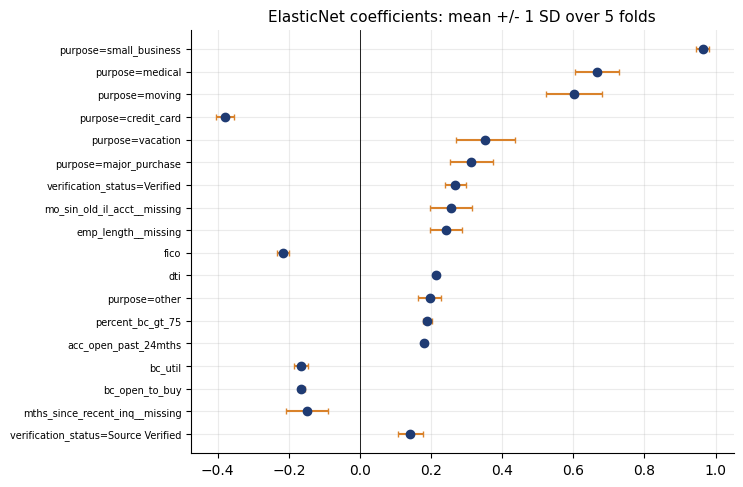

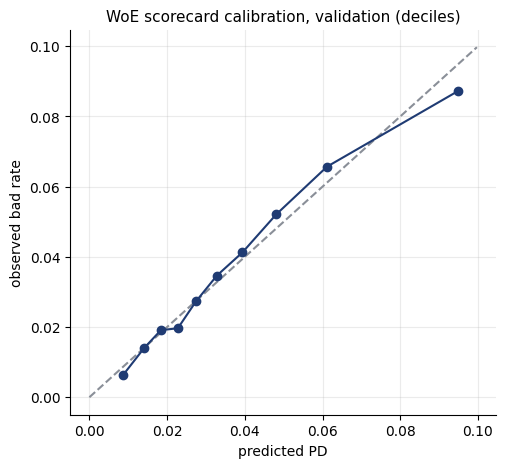

,feature,coef,std_err,p_value,odds_ratio_per_unit_woe,iv
0,const,-3.438050,0.009646,0.000000e+00,0.032127,NaN
1,fico,-0.469448,0.034668,8.901938e-42,0.625347,0.111547
2,acc_open_past_24mths,-0.734055,0.035720,7.633475e-94,0.479959,0.091068
3,annual_inc,-0.248676,0.045300,4.028925e-08,0.779833,0.073893
4,dti,-0.637130,0.036540,4.352052e-68,0.528808,0.073416
5,bc_open_to_buy,-0.192151,0.058120,9.459809e-04,0.825183,0.071832
6,mths_since_recent_inq,-0.443152,0.050352,1.354258e-18,0.642010,0.067709
7,inq_last_6mths,-0.490602,0.048335,3.315158e-24,0.612258,0.066940
8,tot_hi_cred_lim,-0.330087,0.057262,8.188506e-09,0.718861,0.063568
9,purpose,-0.902059,0.042406,2.063657e-100,0.405733,0.049311


In [15]:
# ---- Raw PDs on validation for every model, Platt calibration (validation only), HL test --------------
P_tr, P_va = {}, {}
P_va["plain_lr"] = sm_fit.predict(sm.add_constant(A_va, prepend=True, has_constant="add"))
for k in ("l2", "l1", "elasticnet"):
    P_va[k + "_lr"] = lr_models[k].predict_proba(A_va)[:, 1]
P_va["woe_scorecard"] = sc.raw_pd(Xva)
P_tr["woe_scorecard"] = sc.raw_pd(Xtr)

def fit_platt(p_raw, y):
    m = LogisticRegression(C=1e6, max_iter=500).fit(L.logit(p_raw).reshape(-1, 1), y)
    return {"a": float(m.intercept_[0]), "b": float(m.coef_[0, 0])}
CAL = {k: fit_platt(v, yva) for k, v in P_va.items()}
sc.cal = CAL["woe_scorecard"]
hl = {k: L.hosmer_lemeshow(yva, L.platt_apply(v, CAL[k])) for k, v in P_va.items()}
hl["woe_scorecard_UNcalibrated"] = L.hosmer_lemeshow(yva, P_va["woe_scorecard"])
save_json(hl, "hosmer_lemeshow_valid.json")
lad = pd.DataFrame([{"model": k, **{m: L.all_metrics(yva, v)[m] for m in ("auc", "gini", "ks", "brier", "ece")},
                     "brier_calibrated": L.all_metrics(yva, L.platt_apply(v, CAL[k]))["brier"], "ece_calibrated": L.ece(yva, L.platt_apply(v, CAL[k])),
                     "hl_p_value_calibrated": hl[k]["p_value"]} for k, v in P_va.items()])
save_csv(lad, "ladder_metrics_valid.csv"); print(lad.round(4).to_string(index=False))

# coefficient stability: refit the chosen ElasticNet on each of 5 folds
stab = []
for i, (a, b) in enumerate(skf.split(A_t, y_t)):
    m = LogisticRegression(penalty="elasticnet", solver="saga", l1_ratio=best_en["l1_ratio"], C=best_en["C"], max_iter=300, tol=1e-3).fit(A_t[a], y_t[a])
    stab.append(pd.Series(m.coef_[0], index=names_lr, name=f"fold{i + 1}"))
stab = pd.concat(stab, axis=1)
stab_s = pd.DataFrame({"mean": stab.mean(axis=1), "std": stab.std(axis=1), "min": stab.min(axis=1), "max": stab.max(axis=1),
                       "sign_flips": (np.sign(stab.min(axis=1)) != np.sign(stab.max(axis=1))) & (stab.min(axis=1) != 0) & (stab.max(axis=1) != 0)})
stab_s["cv_ratio"] = stab_s["std"] / stab_s["mean"].abs().replace(0, np.nan)
save_csv(stab_s.reset_index().rename(columns={"index": "feature"}), "coef_stability.csv")
top = stab_s.reindex(stab_s["mean"].abs().sort_values(ascending=False).index).head(18).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.errorbar(top["mean"], range(len(top)), xerr=top["std"], fmt="o", color=NAVY, ecolor=ORANGE, capsize=2)
ax.set_yticks(range(len(top))); ax.set_yticklabels(top.index, fontsize=7); ax.axvline(0, color="k", lw=.6)
ax.set_title("ElasticNet coefficients: mean +/- 1 SD over 5 folds")
savefig(fig, "coef_stability.png", "Tiny whiskers mean the coefficient barely moves when the training data is reshuffled, which is what a stable model looks like.")
fig, ax = plt.subplots(figsize=(5.5, 5)); r = L.reliability_table(yva, L.platt_apply(P_va["woe_scorecard"], CAL["woe_scorecard"]))
ax.plot([0, r.mean_pred.max() * 1.05], [0, r.mean_pred.max() * 1.05], "--", color=GREY); ax.plot(r.mean_pred, r.obs_rate, "o-", color=NAVY)
ax.set_xlabel("predicted PD"); ax.set_ylabel("observed bad rate"); ax.set_title("WoE scorecard calibration, validation (deciles)")
savefig(fig, "calibration_scorecard_valid.png", "Points on the dashed line mean predicted risk equals actual risk. Calibration was fitted on validation, so this is an in-sample check; the real test is OOT.")
sc_tab.head(12)

## Stage 6 - Challenger models: XGBoost tuned, and XGBoost with monotone constraints

**What.** Gradient-boosted trees on all (unpruned) application-time features, hyper-parameters tuned by randomised search with
3-fold CV on a train sub-sample (modest budget), then refit on the full train sample. The second challenger re-uses the
tuned settings but forces a **monotone** relationship with PD for features where business expectation and the train data
agree (e.g. higher FICO never raises PD). SHAP gives global importance and per-applicant reason codes.

**Banker's note.** Trees capture interactions that a scorecard cannot, but they are harder to explain and can learn
counter-intuitive wiggles. Monotone constraints are the standard compromise banks use to make a boosted model defensible
(each variable's effect has the same sign as its scorecard counterpart). The price is a small loss of AUC, which we measure.

**Plain-English note.** We let a more flexible model try to beat the simple one, then tell it "a better credit score may never
make a borrower look riskier" and see how much accuracy that rule costs.

In [16]:
from xgboost import XGBClassifier
import xgboost as xgb
prep_all = L.RawPrep(L.NUMERIC_FEATURES, L.CATEGORICAL_FEATURES).fit(Xtr)
T_tr, tree_names = prep_all.transform_trees(Xtr); T_va, _ = prep_all.transform_trees(Xva)

# constraint rule: business expectation sign, kept only if train univariate direction agrees
direction = {}
for c in L.NUMERIC_FEATURES:
    xs = Xtr[c]; m = xs.notna()
    direction[c] = int(np.sign(stats.spearmanr(xs[m], ytr[m.values])[0])) if m.sum() > 100 else 0
constraint = {c: (L.EXPECTED_SIGN[c] if L.EXPECTED_SIGN[c] == direction[c] else 0) for c in L.NUMERIC_FEATURES}
mono_vec = tuple(int(constraint.get(n, 0)) for n in tree_names)
mono_tab = pd.DataFrame({"feature": L.NUMERIC_FEATURES, "expected_sign": [L.EXPECTED_SIGN[c] for c in L.NUMERIC_FEATURES],
                         "train_spearman_direction": [direction[c] for c in L.NUMERIC_FEATURES], "constraint_applied": [constraint[c] for c in L.NUMERIC_FEATURES]})
save_csv(mono_tab, "monotone_constraints.csv")
# coefficient sign check vs business expectation (numeric features)
plc = plain.set_index("feature").coef
sg = pd.DataFrame({"feature": L.NUMERIC_FEATURES, "label": [L.LABELS[c] for c in L.NUMERIC_FEATURES],
                   "expected_effect_on_pd": [L.EXPECTED_SIGN[c] for c in L.NUMERIC_FEATURES], "train_univariate_direction": [direction[c] for c in L.NUMERIC_FEATURES]})
sg["plain_lr_coef"] = sg.feature.map(plc); sg["scorecard_woe_coef"] = sg.feature.map(sc.coefs)
sg["in_plain_lr"] = sg.plain_lr_coef.notna(); sg["in_scorecard"] = sg.scorecard_woe_coef.notna()
sg["plain_lr_consistent"] = np.where(sg.expected_effect_on_pd == 0, "n/a (unclear expectation)", np.where(~sg.in_plain_lr, "not in model",
                              np.where(np.sign(sg.plain_lr_coef) == sg.expected_effect_on_pd, "yes", "NO")))
sg["scorecard_consistent"] = np.where(~sg.in_scorecard, "not in scorecard", np.where(sg.scorecard_woe_coef < 0, "yes (WoE coef negative)", "NO"))
save_csv(sg, "sign_check.csv"); print(sg.plain_lr_consistent.value_counts().to_string())
print("constrained features:", int((mono_tab.constraint_applied != 0).sum()), "of", len(mono_tab))

space = {"max_depth": [3, 4, 5, 6], "learning_rate": [0.03, 0.05, 0.08], "n_estimators": [200, 350, 500],
         "min_child_weight": [20, 50, 100], "subsample": [0.7, 0.85, 1.0], "colsample_bytree": [0.5, 0.7, 0.9],
         "reg_lambda": [1, 5, 20], "gamma": [0, 1]}
base_xgb = XGBClassifier(tree_method="hist", n_jobs=-1, eval_metric="logloss", random_state=SEED)
rs = RandomizedSearchCV(base_xgb, space, n_iter=3 if FAST else 12, cv=StratifiedKFold(3, shuffle=True, random_state=SEED),
                        scoring="roc_auc", random_state=SEED, n_jobs=1, refit=False)
t = time.time(); rs.fit(T_tr[tune_idx], ytr[tune_idx])
bp = rs.best_params_
srch = pd.DataFrame(rs.cv_results_["params"]); srch["cv_auc_mean"] = rs.cv_results_["mean_test_score"]; srch["cv_auc_std"] = rs.cv_results_["std_test_score"]
save_csv(srch.sort_values("cv_auc_mean", ascending=False), "xgb_search.csv"); save_json(bp, "xgb_best_params.json")
tick(f"xgb search done in {(time.time() - t) / 60:.1f} min; best CV AUC {rs.best_score_:.4f}; params {bp}")

xgb_tuned = XGBClassifier(**bp, tree_method="hist", n_jobs=-1, eval_metric="logloss", random_state=SEED).fit(T_tr, ytr)
xgb_mono = XGBClassifier(**bp, tree_method="hist", n_jobs=-1, eval_metric="logloss", random_state=SEED, monotone_constraints=mono_vec).fit(T_tr, ytr)
P_va["xgb_tuned"] = xgb_tuned.predict_proba(T_va)[:, 1]
P_va["xgb_monotone"] = xgb_mono.predict_proba(T_va)[:, 1]

# reference only: the same booster WITH LendingClub's own grade / sub-grade / int_rate (not deployable by design)
def lc_extra(idx):
    d = D.iloc[idx]
    return np.column_stack([d["int_rate"].astype(float).values, d["grade"].map({g: i for i, g in enumerate("ABCDEFG", 1)}).values.astype(float),
                            (d["grade"].map({g: i for i, g in enumerate("ABCDEFG")}).values * 5 + d["sub_grade"].str[1].astype(float).values)])
E_tr, E_va = lc_extra(tr_idx), lc_extra(va_idx)
xgb_lc = XGBClassifier(**bp, tree_method="hist", n_jobs=-1, eval_metric="logloss", random_state=SEED).fit(np.hstack([T_tr, E_tr]), ytr)
P_va["ref_xgb_plus_LC_grade"] = xgb_lc.predict_proba(np.hstack([T_va, E_va]))[:, 1]
P_va["ref_LC_subgrade_only"] = 1 / (1 + np.exp(-(E_va[:, 2] - 15) / 6))      # monotone transform of sub-grade rank, used for ranking metrics only
for k in ("xgb_tuned", "xgb_monotone", "ref_xgb_plus_LC_grade", "ref_LC_subgrade_only"):
    CAL[k] = fit_platt(P_va[k], yva)
print({k: round(roc_auc_score(yva, v), 4) for k, v in P_va.items()})

plain_lr_consistent
not in model                 29
yes                          15
n/a (unclear expectation)    13
NO                            2
constrained features: 41 of 59
[   5.4 min] xgb search done in 2.3 min; best CV AUC 0.7024; params {'subsample': 0.7, 'reg_lambda': 20, 'n_estimators': 350, 'min_child_weight': 100, 'max_depth': 4, 'learning_rate': 0.05, 'gamma': 1, 'colsample_bytree': 0.9}
{'plain_lr': np.float64(0.6937), 'l2_lr': np.float64(0.6937), 'l1_lr': np.float64(0.6935), 'elasticnet_lr': np.float64(0.6937), 'woe_scorecard': np.float64(0.6912), 'xgb_tuned': np.float64(0.7208), 'xgb_monotone': np.float64(0.7179), 'ref_xgb_plus_LC_grade': np.float64(0.7433), 'ref_LC_subgrade_only': np.float64(0.72)}


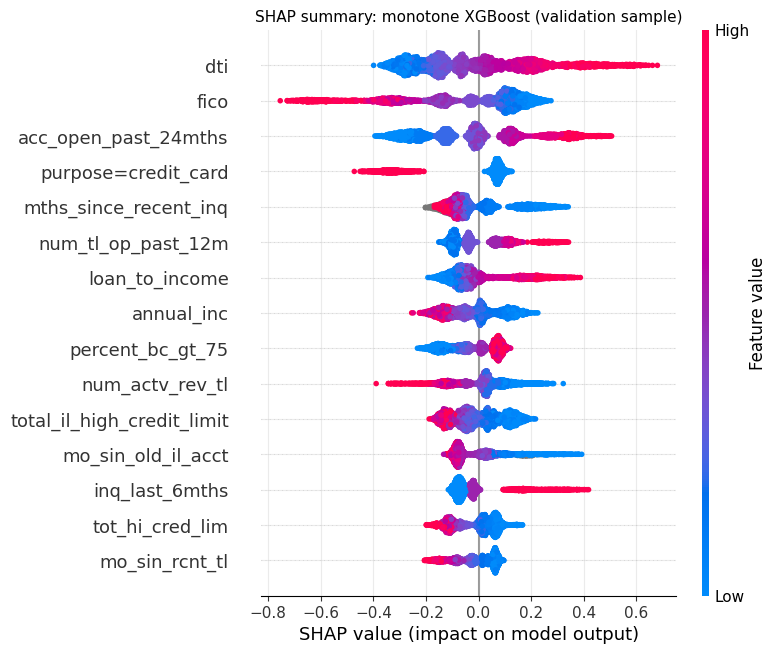

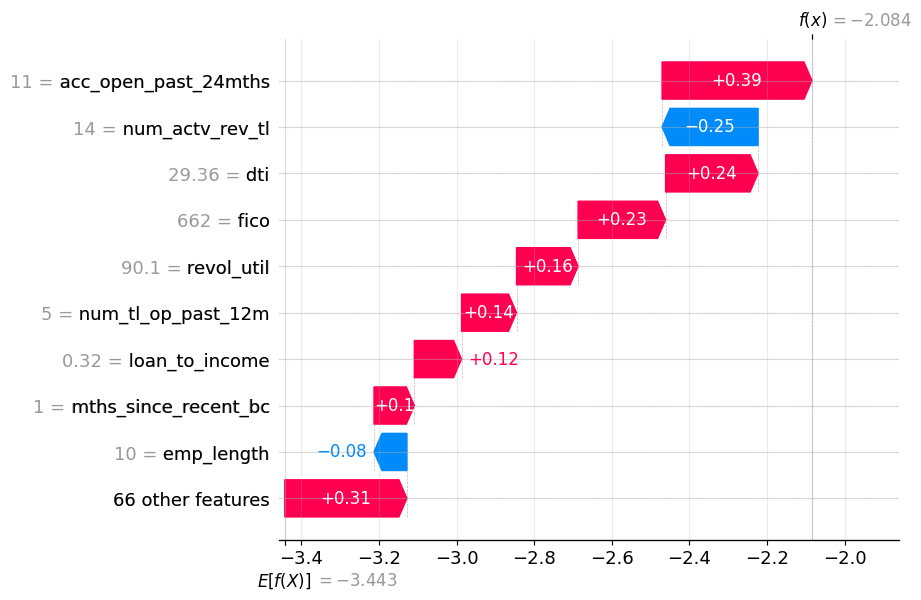

,feature,mean_abs_shap_tuned,mean_abs_shap_monotone
3,dti,0.179937,0.185692
5,fico,0.197443,0.184581
22,acc_open_past_24mths,0.171177,0.167592
66,purpose=credit_card,0.130606,0.140417
35,mths_since_recent_inq,0.096362,0.098845
50,num_tl_op_past_12m,0.094048,0.091756
4,loan_to_income,0.086028,0.089846
2,annual_inc,0.075461,0.086212
52,percent_bc_gt_75,0.099871,0.084066
39,num_actv_rev_tl,0.049364,0.082561


In [17]:
# ---- SHAP via XGBoost's native TreeSHAP (exact, no extra dependency issues) ----------------------
import shap
sh_idx = np.random.default_rng(SEED).choice(len(T_va), min(len(T_va), 4000 if not FAST else 1000), replace=False)
def contribs(model, M):
    return model.get_booster().predict(xgb.DMatrix(M, feature_names=None), pred_contribs=True)
S_mono = contribs(xgb_mono, T_va[sh_idx]); S_tuned = contribs(xgb_tuned, T_va[sh_idx])
imp = pd.DataFrame({"feature": tree_names, "mean_abs_shap_tuned": np.abs(S_tuned[:, :-1]).mean(0), "mean_abs_shap_monotone": np.abs(S_mono[:, :-1]).mean(0)})
imp = imp.sort_values("mean_abs_shap_monotone", ascending=False); save_csv(imp, "shap_importance.csv")
plt.figure(figsize=(8, 6.5))
shap.summary_plot(S_mono[:, :-1], pd.DataFrame(T_va[sh_idx], columns=tree_names), max_display=15, show=False, plot_size=None)
plt.title("SHAP summary: monotone XGBoost (validation sample)")
savefig(plt.gcf(), "shap_beeswarm.png", "Each dot is a borrower. Right = pushes predicted default risk up, left = down; red = high value of the feature. Higher FICO (red) sits on the left, as it should.")
# local explanation for one OOT-like high-risk borrower from validation
j = int(np.argsort(P_va["xgb_monotone"][sh_idx])[-len(sh_idx) // 50])
expl = shap.Explanation(values=S_mono[j, :-1], base_values=S_mono[j, -1], data=T_va[sh_idx][j], feature_names=tree_names)
plt.figure(); shap.plots.waterfall(expl, max_display=10, show=False)
savefig(plt.gcf(), "shap_waterfall.png", "How one applicant's risk is built up: each bar is a feature pushing the log-odds of default up (red) or down (blue) from the average borrower. These become the reason codes.")
imp.head(10)

## Stage 7 - Comparison and the frozen champion rule

**Order of operations (this is the point of an out-of-time test).**
1. Score **validation only**: AUC, Gini, KS, PR-AUC, Brier, ECE, with Platt calibration fitted on validation.
2. **Freeze the champion rule** and the chosen champion, and write it to `champion_rule.json` with a hash, *before the 2016 OOT file is touched*.
3. Only then score OOT, report every model, compute PSI/CSI and paired-bootstrap confidence intervals (1000 resamples) for the AUC difference against the champion.

**Rule.** Candidates: WoE scorecard, ElasticNet LR, XGB-monotone. The XGB-monotone model is champion only if its validation AUC beats the
best interpretable candidate by at least 0.010 **and** the 95% bootstrap interval of that gap excludes zero. Otherwise the best interpretable candidate wins,
with the WoE scorecard preferred when it is within 0.005 AUC of ElasticNet (because a points table is directly auditable).
The plain XGBoost and the LendingClub-grade variant are shown for reference but are not eligible.

**Banker's note.** A model risk reviewer (SR 11-7 / PRA SS1/23 style) wants the selection logic fixed ahead of the test so the test
is a genuine out-of-sample, out-of-time check and not another round of model shopping.

**Plain-English note.** Before looking at the final exam, we write down exactly how we will pick the winner, seal it, then grade.

In [18]:
def paired_boot(y, P, ref, B, seed=0, names=None):
    names = names or list(P)
    r = np.random.default_rng(seed); n = len(y); y = np.asarray(y)
    out = {k: [] for k in names}; ref_a = []
    for _ in range(B):
        ix = r.integers(0, n, n); yb = y[ix]
        if yb.sum() == 0 or yb.sum() == n: continue
        ref_a.append(L.auc_fast(yb, P[ref][ix]))
        for k in names:
            out[k].append(L.auc_fast(yb, P[k][ix]))
    ref_a = np.array(ref_a)
    rows = []
    for k in names:
        d = np.array(out[k]) - ref_a
        rows.append({"model": k, "auc_diff_vs_" + ref: float(np.mean(out[k]) - ref_a.mean()), "ci_low": float(np.percentile(d, 2.5)), "ci_high": float(np.percentile(d, 97.5)),
                     "auc_ci_low": float(np.percentile(out[k], 2.5)), "auc_ci_high": float(np.percentile(out[k], 97.5)), "boot_reps": len(d)})
    return pd.DataFrame(rows)

CANDS = ["woe_scorecard", "elasticnet_lr", "xgb_monotone"]
val_cmp = pd.DataFrame([{"model": k, **L.all_metrics(yva, L.platt_apply(v, CAL[k])), "auc_raw": roc_auc_score(yva, v)} for k, v in P_va.items()])
save_csv(val_cmp, "model_metrics_valid.csv")
t = time.time(); bv = paired_boot(yva, P_va, "woe_scorecard", 200 if not FAST else 50, names=CANDS)
save_csv(bv, "bootstrap_valid_candidates.csv"); tick(f"validation bootstrap {(time.time() - t):.0f}s")
vm = val_cmp.set_index("model")
interp = ["woe_scorecard", "elasticnet_lr"]
best_interp = max(interp, key=lambda k: vm.loc[k, "auc"])
if abs(vm.loc["woe_scorecard", "auc"] - vm.loc["elasticnet_lr", "auc"]) <= 0.005: best_interp = "woe_scorecard"
gap = vm.loc["xgb_monotone", "auc"] - vm.loc[best_interp, "auc"]
bg = paired_boot(yva, P_va, best_interp, 200 if not FAST else 50, names=["xgb_monotone"]).iloc[0]
champion = "xgb_monotone" if (gap >= 0.010 and bg["ci_low"] > 0) else best_interp
rule = {"frozen_at_utc": pd.Timestamp.now("UTC").isoformat(), "scored_on": "validation only (OOT 2016 not yet scored)",
        "candidates": CANDS, "not_eligible": ["xgb_tuned", "ref_xgb_plus_LC_grade", "ref_LC_subgrade_only", "plain_lr", "l1_lr", "l2_lr"],
        "rule": ("XGB-monotone wins only if validation AUC exceeds the best interpretable candidate by >= 0.010 AND the paired-bootstrap 95% CI of the gap excludes 0; "
                 "otherwise the best interpretable candidate wins; WoE scorecard preferred if within 0.005 AUC of ElasticNet."),
        "validation_auc": {k: float(vm.loc[k, "auc"]) for k in CANDS}, "best_interpretable": best_interp,
        "xgb_monotone_gap_vs_best_interpretable": float(gap), "gap_ci95": [float(bg["ci_low"]), float(bg["ci_high"])], "champion": champion}
rule["sha256_of_rule_body"] = hashlib.sha256(json.dumps(rule, sort_keys=True).encode()).hexdigest()
save_json(rule, "champion_rule.json")
save_json(CAL, "calibrators.json")
print(json.dumps(rule, indent=1))

[   6.7 min] validation bootstrap 16s
{
 "frozen_at_utc": "2026-10-30T22:33:48.673734+00:00",
 "scored_on": "validation only (OOT 2016 not yet scored)",
 "candidates": [
  "woe_scorecard",
  "elasticnet_lr",
  "xgb_monotone"
 ],
 "not_eligible": [
  "xgb_tuned",
  "ref_xgb_plus_LC_grade",
  "ref_LC_subgrade_only",
  "plain_lr",
  "l1_lr",
  "l2_lr"
 ],
 "rule": "XGB-monotone wins only if validation AUC exceeds the best interpretable candidate by >= 0.010 AND the paired-bootstrap 95% CI of the gap excludes 0; otherwise the best interpretable candidate wins; WoE scorecard preferred if within 0.005 AUC of ElasticNet.",
 "validation_auc": {
  "woe_scorecard": 0.6912247974142983,
  "elasticnet_lr": 0.6937135173783924,
  "xgb_monotone": 0.7179461051839708
 },
 "best_interpretable": "woe_scorecard",
 "xgb_monotone_gap_vs_best_interpretable": 0.02672130776967252,
 "gap_ci95": [
  0.022610931659910984,
  0.0308780540783506
 ],
 "champion": "xgb_monotone",
 "sha256_of_rule_body": "7f52d16fe1730e

## Stage 7b - Out-of-time scoring (2016 issues): the out-of-time test

Everything below is computed on loans issued in **2016**, using only objects fixed above: bins, coefficients, hyper-parameters,
calibrators, and the champion rule.

**Banker's note.** Expect a lower Gini than validation, because the economy and LendingClub's own underwriting shifted. Calibration (Platt) is fitted on
**validation only** and never on OOT; because the 12-month label is complete for every vintage (no right-censoring), any remaining gap between predicted and
observed PD in 2016 is genuine vintage drift, not a labelling artefact. It is reported as it is: that is exactly what monitoring and recalibration are for.

**Plain-English note.** This is the real-world test: the model has never seen these loans. A drop in accuracy versus the practice run is normal and we show it as-is.

In [19]:
Xoot, yoot = Xall.iloc[oot_idx], yall[oot_idx]
A_oot = prep.transform(Xoot); T_oot, _ = prep_all.transform_trees(Xoot); E_oot = lc_extra(oot_idx)
P_oot = {"plain_lr": sm_fit.predict(sm.add_constant(A_oot, prepend=True, has_constant="add")),
         "l2_lr": lr_models["l2"].predict_proba(A_oot)[:, 1], "l1_lr": lr_models["l1"].predict_proba(A_oot)[:, 1],
         "elasticnet_lr": lr_models["elasticnet"].predict_proba(A_oot)[:, 1], "woe_scorecard": sc.raw_pd(Xoot),
         "xgb_tuned": xgb_tuned.predict_proba(T_oot)[:, 1], "xgb_monotone": xgb_mono.predict_proba(T_oot)[:, 1],
         "ref_xgb_plus_LC_grade": xgb_lc.predict_proba(np.hstack([T_oot, E_oot]))[:, 1],
         "ref_LC_subgrade_only": 1 / (1 + np.exp(-(E_oot[:, 2] - 15) / 6))}
PC_oot = {k: L.platt_apply(v, CAL[k]) for k, v in P_oot.items()}
PC_va = {k: L.platt_apply(v, CAL[k]) for k, v in P_va.items()}
rows = []
for k in P_oot:
    mo = L.all_metrics(yoot, PC_oot[k]); mo["auc"] = roc_auc_score(yoot, P_oot[k]); mo["gini"] = 2 * mo["auc"] - 1; mo["ks"] = L.ks_stat(yoot, P_oot[k])
    mv = L.all_metrics(yva, PC_va[k]); mv["auc"] = roc_auc_score(yva, P_va[k]); mv["gini"] = 2 * mv["auc"] - 1
    kind = "reference" if k.startswith("ref_") else ("champion candidate" if k in CANDS else "ladder / challenger")
    rows.append({"model": k, "role": kind, "is_champion": k == champion, **{f"oot_{m}": mo[m] for m in ("auc", "gini", "ks", "pr_auc", "brier", "ece", "log_loss", "mean_pred", "obs_rate")},
                 "valid_auc": mv["auc"], "valid_gini": mv["gini"], "gini_drop_valid_to_oot": mv["gini"] - mo["gini"]})
cmp_ = pd.DataFrame(rows).sort_values("oot_auc", ascending=False).reset_index(drop=True)
t = time.time(); bo = paired_boot(yoot, P_oot, champion, BOOT, names=list(P_oot)); tick(f"OOT bootstrap {BOOT} reps in {time.time() - t:.0f}s")
cmp_ = cmp_.merge(bo.rename(columns={"auc_diff_vs_" + champion: "auc_diff_vs_champion", "ci_low": "diff_ci_low", "ci_high": "diff_ci_high"}), on="model")
save_csv(cmp_, "model_comparison.csv")
print(cmp_[["model", "role", "is_champion", "oot_auc", "oot_gini", "oot_ks", "oot_brier", "oot_ece", "auc_diff_vs_champion", "diff_ci_low", "diff_ci_high"]].round(4).to_string(index=False))

[  17.5 min] OOT bootstrap 1000 reps in 629s
                model                role  is_champion  oot_auc  oot_gini  oot_ks  oot_brier  oot_ece  auc_diff_vs_champion  diff_ci_low  diff_ci_high
ref_xgb_plus_LC_grade           reference        False   0.7249    0.4498  0.3279     0.0401   0.0044                0.0290       0.0265        0.0315
 ref_LC_subgrade_only           reference        False   0.7061    0.4123  0.3011     0.0405   0.0048                0.0102       0.0063        0.0142
            xgb_tuned ladder / challenger        False   0.6983    0.3965  0.2872     0.0406   0.0067                0.0024       0.0015        0.0033
         xgb_monotone  champion candidate         True   0.6959    0.3918  0.2823     0.0406   0.0068                0.0000       0.0000        0.0000
                l2_lr ladder / challenger        False   0.6727    0.3454  0.2476     0.0409   0.0069               -0.0232      -0.0256       -0.0207
             plain_lr ladder / challenger        

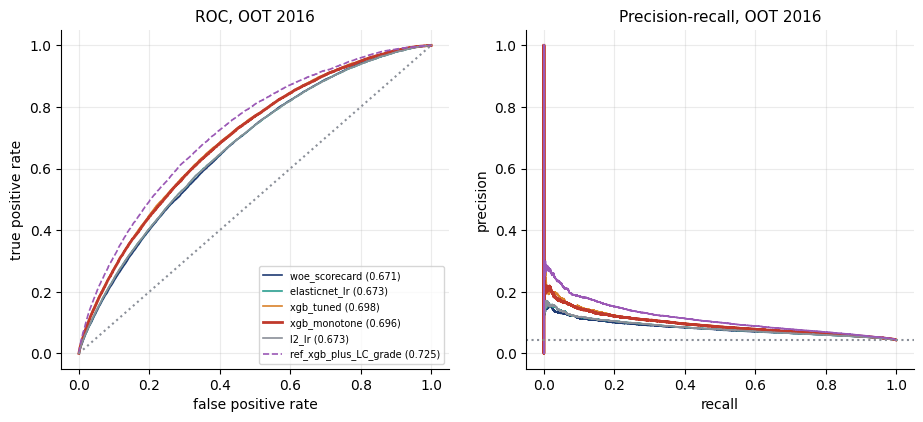

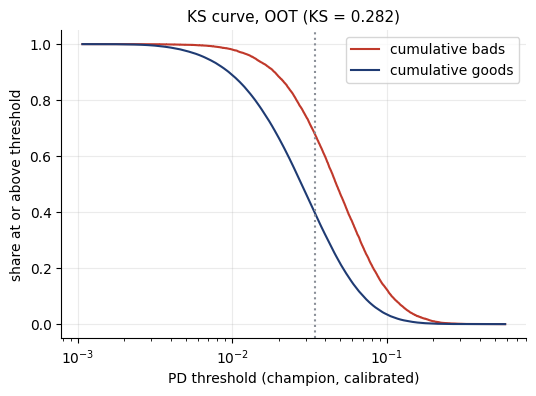

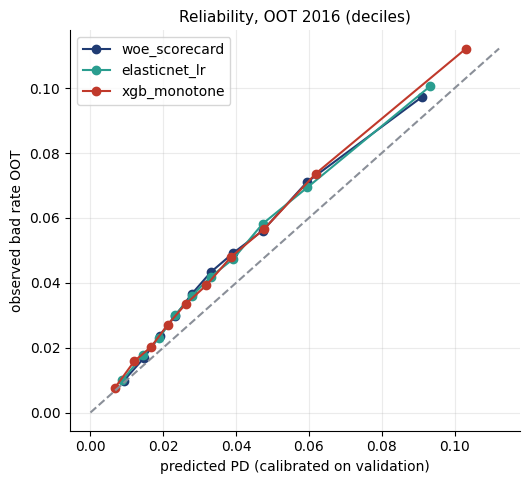

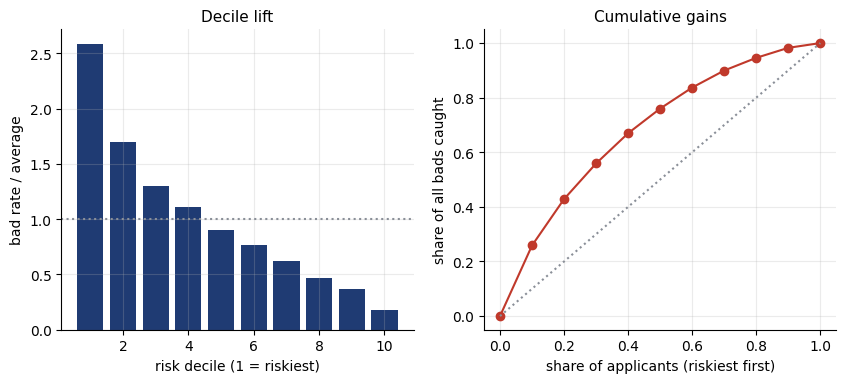

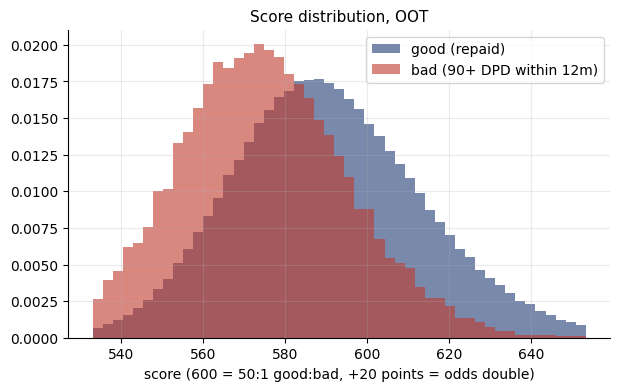

,decile,n,mean_pd,bad_rate,bads,lift,cum_bad_capture,cum_pop
0,10,31828,0.103,0.112,3572,2.587,0.259,0.1
1,9,31828,0.062,0.074,2346,1.699,0.429,0.2
2,8,31827,0.048,0.057,1801,1.304,0.559,0.3
3,7,31828,0.039,0.048,1528,1.107,0.670,0.4
4,6,31827,0.032,0.039,1247,0.903,0.760,0.5
5,5,31828,0.026,0.033,1064,0.771,0.837,0.6
6,4,31828,0.021,0.027,861,0.624,0.899,0.7
7,3,31827,0.017,0.020,642,0.465,0.946,0.8
8,2,31828,0.012,0.016,506,0.366,0.983,0.9
9,1,31828,0.007,0.008,241,0.175,1.000,1.0


In [20]:
# ---- Curves: ROC, KS, PR, reliability, lift/gains, score distribution --------------------------------
show = ["woe_scorecard", "elasticnet_lr", "xgb_tuned", "xgb_monotone", "l2_lr", "ref_xgb_plus_LC_grade"]
colors = dict(zip(show, [NAVY, TEAL, ORANGE, RED, GREY, "#9b59b6"]))
roc_rows, pr_rows = [], []
fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
for k in show:
    f, t_, _ = roc_curve(yoot, PC_oot[k]); ax[0].plot(f, t_, color=colors[k], label=f"{k} ({roc_auc_score(yoot, PC_oot[k]):.3f})", lw=2 if k == champion else 1.2, ls="--" if k.startswith("ref_") else "-")
    sel = np.linspace(0, len(f) - 1, 200).astype(int); roc_rows += [{"model": k, "fpr": a, "tpr": b} for a, b in zip(f[sel], t_[sel])]
    p_, r_, _ = precision_recall_curve(yoot, PC_oot[k]); sel = np.linspace(0, len(p_) - 1, 200).astype(int); pr_rows += [{"model": k, "recall": a, "precision": b} for a, b in zip(r_[sel], p_[sel])]
    ax[1].plot(r_, p_, color=colors[k], label=k, lw=2 if k == champion else 1.2)
ax[0].plot([0, 1], [0, 1], ":", color=GREY); ax[0].set_xlabel("false positive rate"); ax[0].set_ylabel("true positive rate"); ax[0].set_title("ROC, OOT 2016"); ax[0].legend(fontsize=7)
ax[1].axhline(yoot.mean(), ls=":", color=GREY); ax[1].set_xlabel("recall"); ax[1].set_ylabel("precision"); ax[1].set_title("Precision-recall, OOT 2016")
save_csv(pd.DataFrame(roc_rows), "roc_points.csv"); save_csv(pd.DataFrame(pr_rows), "pr_points.csv")
savefig(fig, "roc_pr_oot.png", "ROC: further toward the top-left is better. Models are close to each other; the dashed purple line uses LendingClub's own grade as an input and shows how much of the gap is just LC's risk model.")

ch = PC_oot[champion]; order = np.argsort(ch); f, t_, thr = roc_curve(yoot, ch)
ksx = np.linspace(0, 1, len(f)); fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(thr[1:], t_[1:], label="cumulative bads", color=RED); ax.plot(thr[1:], f[1:], label="cumulative goods", color=NAVY)
kk = np.argmax(t_ - f); ax.axvline(thr[kk], ls=":", color=GREY); ax.set_xscale("log"); ax.set_xlabel("PD threshold (champion, calibrated)"); ax.set_ylabel("share at or above threshold")
ax.set_title(f"KS curve, OOT (KS = {np.max(t_ - f):.3f})"); ax.legend()
ks_pts = pd.DataFrame({"threshold": thr[1:], "tpr": t_[1:], "fpr": f[1:]}); save_csv(ks_pts.iloc[np.linspace(0, len(ks_pts) - 1, 300).astype(int)], "ks_points.csv")
savefig(fig, "ks_curve.png", "KS is the widest vertical gap between the share of bad and good borrowers caught at a threshold. A bigger gap means better separation.")

rel_rows = []
fig, ax = plt.subplots(figsize=(5.8, 5.2)); mx = 0
for k in ["woe_scorecard", "elasticnet_lr", "xgb_monotone"]:
    r = L.reliability_table(yoot, PC_oot[k]); r["model"] = k; rel_rows.append(r); ax.plot(r.mean_pred, r.obs_rate, "o-", color=colors[k], label=k); mx = max(mx, r.mean_pred.max(), r.obs_rate.max())
ax.plot([0, mx], [0, mx], "--", color=GREY); ax.set_xlabel("predicted PD (calibrated on validation)"); ax.set_ylabel("observed bad rate OOT"); ax.legend(); ax.set_title("Reliability, OOT 2016 (deciles)")
save_csv(pd.concat(rel_rows), "reliability_oot.csv")
savefig(fig, "reliability_oot.png", "Points on the dashed line mean predicted PD equals the observed 2016 bad rate; above it the model under-predicted risk, below it over-predicted. Calibration was fitted on validation only.")

dec = pd.DataFrame({"pd": ch, "y": yoot}); dec["decile"] = pd.qcut(dec.pd.rank(method="first"), 10, labels=range(1, 11)).astype(int)
lift = dec.groupby("decile").agg(n=("y", "size"), mean_pd=("pd", "mean"), bad_rate=("y", "mean"), bads=("y", "sum")).reset_index()
lift["lift"] = lift.bad_rate / yoot.mean(); lift = lift.sort_values("decile", ascending=False).reset_index(drop=True)
lift["cum_bad_capture"] = lift.bads.cumsum() / lift.bads.sum(); lift["cum_pop"] = lift.n.cumsum() / lift.n.sum()
save_csv(lift, "lift_deciles.csv")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.9))
ax[0].bar(lift.index + 1, lift.lift, color=NAVY); ax[0].axhline(1, ls=":", color=GREY); ax[0].set_xlabel("risk decile (1 = riskiest)"); ax[0].set_ylabel("bad rate / average"); ax[0].set_title("Decile lift")
ax[1].plot([0] + lift.cum_pop.tolist(), [0] + lift.cum_bad_capture.tolist(), "o-", color=RED); ax[1].plot([0, 1], [0, 1], ":", color=GREY)
ax[1].set_xlabel("share of applicants (riskiest first)"); ax[1].set_ylabel("share of all bads caught"); ax[1].set_title("Cumulative gains")
savefig(fig, "lift_gains.png", "The riskiest 10% of applicants default at a multiple of the average rate, and the riskiest 30% contain a disproportionate share of all bad loans.")

scr = L.pd_to_score(ch)
fig, ax = plt.subplots(figsize=(7, 4)); bins = np.linspace(np.percentile(scr, .5), np.percentile(scr, 99.5), 50)
ax.hist(scr[yoot == 0], bins, alpha=.6, color=NAVY, density=True, label="good (repaid)"); ax.hist(scr[yoot == 1], bins, alpha=.6, color=RED, density=True, label="bad (90+ DPD within 12m)")
ax.set_xlabel("score (600 = 50:1 good:bad, +20 points = odds double)"); ax.set_title("Score distribution, OOT"); ax.legend()
savefig(fig, "score_distribution.png", "Good borrowers (blue) sit to the right of bad borrowers (red) but the two overlap a lot, which is normal for unsecured consumer credit and explains a Gini well below 0.8.")
lift.round(3)

## Stage 7c - Drift: PSI / CSI, score drift, and the label-definition sensitivity

**What.** Population Stability Index compares the distribution of the score (and of each input, called CSI) in train against OOT:
PSI < 0.10 stable, 0.10-0.25 watch, > 0.25 significant shift. We also (a) trace predicted vs actual bad rate by issue quarter, and
(b) re-label the same 2016 loans under alternative default definitions (looser 12-month proxy; the old lifetime resolved-only label) to see how much the label choice matters.

**Banker's note.** PSI says the *population* moved; the quarterly predicted-vs-actual shows the *relationship* moved. A model can have a
stable PSI and still be miscalibrated (and vice versa), so monitoring needs both.

**Plain-English note.** "Are today's applicants the same kind of people as the ones we trained on, and is the model still right about how risky they are?"

{'champion': 'xgb_monotone', 'psi_train_vs_valid': 0.005150386042784755, 'psi_train_vs_oot': 0.001162870492211629, 'psi_valid_vs_oot': 0.003554143803252402, 'mean_score_train': 590.070723929404, 'mean_score_valid': 590.2497327895098, 'mean_score_oot': 589.7224572024653, 'mean_pd_train': 0.03597882920738693, 'mean_pd_oot': 0.03658871227384404, 'label_train_vs_oot': 'stable (<0.10)'}


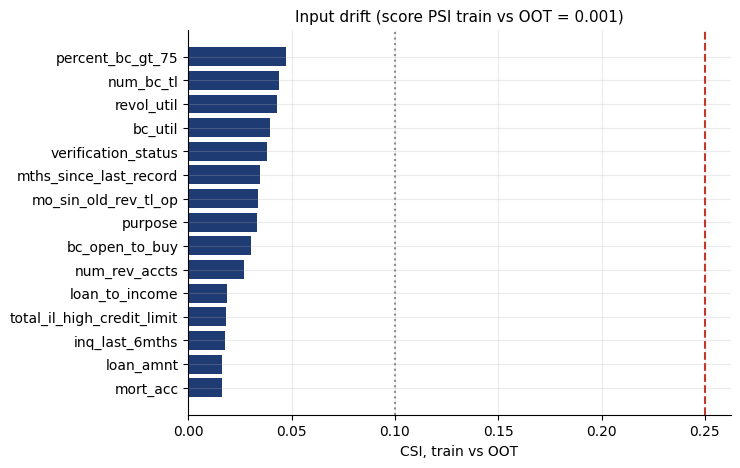

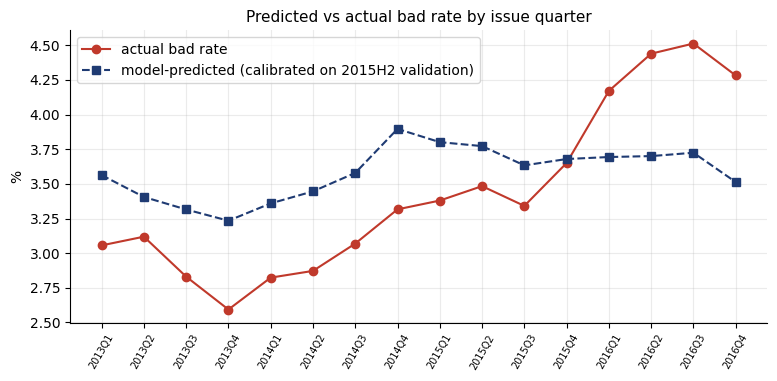

{'champion': 'xgb_monotone',
 'definition': 'bad = Charged Off/Default AND last payment <= month 9 on book (90+ DPD within 12 months)',
 'oot_loans_total': 318277,
 'oot_loans_dropped_by_label': 0,
 'oot_bad_rate_main': 0.04338359353644781,
 'oot_auc_main': 0.6959023971085697,
 'oot_bad_rate_window_lastpay_le_12': 0.06318709803096045,
 'oot_auc_window_lastpay_le_12': 0.6897565607795898,
 'oot_share_open_at_cut': 0.2810884858158146,
 'oot_n_old_label_resolved': 228813,
 'oot_bad_rate_old_lifetime_resolved_only': 0.1984939666889556,
 'oot_auc_old_lifetime_resolved_only': 0.6795077397520826,
 'oot_mean_pred_champion': 0.03658871227384404,
 'matured_2013_14_lifetime_bad_rate': 0.1319165601995498,
 'matured_2013_14_12m_bad_rate': 0.0296929184157693,
 'lifetime_to_12m_ratio_matured': 4.442694327058523,
 'note': 'Same champion, same 2016 loans, three label definitions. Ranking power (AUC) is similar; only the bad-rate LEVEL depends on the definition. The old label dropped the loans still open

In [21]:
# champion-agnostic score PSI: use the champion's calibrated PD on train too
def champ_raw(Xdf, A, T):
    return {"woe_scorecard": lambda: sc.raw_pd(Xdf), "elasticnet_lr": lambda: lr_models["elasticnet"].predict_proba(A)[:, 1],
            "xgb_monotone": lambda: xgb_mono.predict_proba(T)[:, 1]}[champion]()
ch_tr = L.platt_apply(champ_raw(Xtr, A_tr, T_tr), CAL[champion]); ch_va = PC_va[champion]
S_tr, S_va, S_oot = L.pd_to_score(ch_tr), L.pd_to_score(ch_va), L.pd_to_score(ch)
psi_score = {"champion": champion, "psi_train_vs_valid": L.psi_numeric(S_tr, S_va), "psi_train_vs_oot": L.psi_numeric(S_tr, S_oot), "psi_valid_vs_oot": L.psi_numeric(S_va, S_oot),
             "mean_score_train": float(S_tr.mean()), "mean_score_valid": float(S_va.mean()), "mean_score_oot": float(S_oot.mean()),
             "mean_pd_train": float(ch_tr.mean()), "mean_pd_oot": float(ch.mean())}
psi_score["label_train_vs_oot"] = L.psi_label(psi_score["psi_train_vs_oot"])
save_json(psi_score, "psi_score.json"); print(psi_score)
csi = []
for c in L.ALL_FEATURES:
    v = L.psi_categorical(Xtr[c], Xoot[c]) if c in L.CATEGORICAL_FEATURES else L.psi_numeric(Xtr[c], Xoot[c])
    csi.append({"feature": c, "label": L.LABELS[c], "csi_train_vs_oot": v, "flag": L.psi_label(v), "in_scorecard": c in sc_vars, "iv": ivmap.get(c, np.nan)})
csi = pd.DataFrame(csi).sort_values("csi_train_vs_oot", ascending=False); save_csv(csi, "csi.csv")
top = csi.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 5)); ax.barh(top.feature, top.csi_train_vs_oot, color=[RED if v > .25 else ORANGE if v > .1 else NAVY for v in top.csi_train_vs_oot])
ax.axvline(.1, ls=":", color=GREY); ax.axvline(.25, ls="--", color=RED); ax.set_xlabel("CSI, train vs OOT"); ax.set_title(f"Input drift (score PSI train vs OOT = {psi_score['psi_train_vs_oot']:.3f})")
savefig(fig, "psi_bar.png", "Bars show how far each input's distribution moved between the training years and 2016. Under 0.10 is stable; over 0.25 would trigger investigation.")

# predicted vs actual by quarter (development + OOT), champion
q_all = pd.DataFrame({"issue_d": D.issue_d.values, "y": yall})
sub = np.concatenate([tr_idx, va_idx, oot_idx]); Xq = Xall.iloc[sub]
Aq, Tq = prep.transform(Xq), prep_all.transform_trees(Xq)[0]
pq = L.platt_apply(champ_raw(Xq, Aq, Tq), CAL[champion])
qd = pd.DataFrame({"quarter": pd.PeriodIndex(D.issue_d.iloc[sub], freq="Q").astype(str), "y": yall[sub], "pd": pq, "set": np.where(np.isin(sub, tr_idx), "train", np.where(np.isin(sub, va_idx), "valid", "OOT"))})
qt = qd.groupby("quarter").agg(n=("y", "size"), actual=("y", "mean"), predicted=("pd", "mean"), set=("set", "first")).reset_index(); qt["score"] = L.pd_to_score(qt.predicted)
save_csv(qt, "drift_by_quarter.csv")
fig, ax = plt.subplots(figsize=(9, 3.8)); ax.plot(qt.quarter, qt.actual * 100, "o-", color=RED, label="actual bad rate"); ax.plot(qt.quarter, qt.predicted * 100, "s--", color=NAVY, label="model-predicted (calibrated on 2015H2 validation)")
ax.set_xticks(range(len(qt))); ax.set_xticklabels(qt.quarter, rotation=60, fontsize=7); ax.set_ylabel("%"); ax.legend(); ax.set_title("Predicted vs actual bad rate by issue quarter")
savefig(fig, "drift_by_quarter.png", "Predicted versus actual 12-month bad rate by issue quarter. Calibration was fitted on 2015H2 only; the 2016 quarters are out of time.")

# label-definition sensitivity on the SAME 2016 loans scored by the champion (the model is not refitted)
o_ = D.iloc[oot_idx]; st_o = o_["loan_status"]; mob_o = o_["mob_last_pay"].values
y_loose = L.label_12m(st_o, mob_o, 12)                                    # also counts stop-paying in months 10-12
res_mask = st_o.isin(L.BAD_STATUS + L.GOOD_STATUS).values                 # OLD label: lifetime, resolved loans only
y_life = st_o.isin(L.BAD_STATUS).values[res_mask].astype(int)
mat = base[base.year.isin([2013, 2014])]                                  # vintages fully matured (36m + data cut)
life_mat = float(mat["loan_status"].isin(L.BAD_STATUS).mean()); w12_mat = float(mat["y"].mean())
cens = {"champion": champion, "definition": "bad = Charged Off/Default AND last payment <= month %d on book (90+ DPD within %d months)" % (L.BAD_MAX_MOB, L.PERF_WINDOW_MONTHS),
        "oot_loans_total": int(len(o_)), "oot_loans_dropped_by_label": 0,
        "oot_bad_rate_main": float(yoot.mean()), "oot_auc_main": float(roc_auc_score(yoot, ch)),
        "oot_bad_rate_window_lastpay_le_12": float(y_loose.mean()), "oot_auc_window_lastpay_le_12": float(roc_auc_score(y_loose, ch)),
        "oot_share_open_at_cut": float(1 - res_mask.mean()), "oot_n_old_label_resolved": int(res_mask.sum()),
        "oot_bad_rate_old_lifetime_resolved_only": float(y_life.mean()), "oot_auc_old_lifetime_resolved_only": float(roc_auc_score(y_life, ch[res_mask])),
        "oot_mean_pred_champion": float(ch.mean()),
        "matured_2013_14_lifetime_bad_rate": life_mat, "matured_2013_14_12m_bad_rate": w12_mat, "lifetime_to_12m_ratio_matured": life_mat / w12_mat,
        "note": "Same champion, same 2016 loans, three label definitions. Ranking power (AUC) is similar; only the bad-rate LEVEL depends on the definition. The old label dropped the loans still open at the data cut."}
save_json(cens, "label_sensitivity.json"); cens

## Stage 8 - Business layer: master scale, grade backtest, cut-off economics, monitoring

**Master scale.** Eight grades (A = safest ... H = riskiest) from **geometric** PD bands, cut-points fixed on validation from the champion's calibrated PD. The
grade PD is the validation mean PD of the grade. On OOT we run a **binomial test** per grade (H0: true default rate = grade PD).

**Cut-off.** Approve if PD <= cut-off. Economics are **assumed, not observed** (public data has no pricing/cost data) and sit on the same **12-month horizon as the label**: a good loan earns a net margin of
a fixed % of principal over the 12 months; a bad loan loses EAD x LGD x principal. Losses that arrive after month 12 are outside the label, so the cut-off is optimistic about the riskiest borrowers
(see the lifetime-to-12-month ratio in Stage 7c); read the profit curve as a trade-off illustration. Cut-off is chosen on validation and then evaluated on OOT.

**Banker's note.** With hundreds of thousands of loans, the binomial test rejects almost any small gap, and defaults within a vintage are correlated (same economy), so the
test over-rejects; read it as a drift alarm together with the size of the gap, not as a pass/fail on its own.

**Reject inference.** LendingClub's file contains only *accepted* loans. Applicants who were declined have no outcome, so the model describes
"people LendingClub approved". Applied to the full through-the-door population it would be biased (typically optimistic for the riskiest applicants).
A production build would add reject inference (parcelling / fuzzy augmentation / bureau performance of rejects); this is **not done here** and is a stated limitation.

**Plain-English note.** We bucket borrowers into eight risk bands, check that each band's real default rate matches what we promised, and show how the
profit changes as the lender gets pickier. The profit numbers use stated assumptions - they illustrate the trade-off, they are not a forecast.

grade  pd_lower  pd_upper  master_scale_pd  share_oot  observed_rate_oot  binomial_p_two_sided          verdict_oot
    A    0.0000    0.0052           0.0039     0.0258             0.0044                0.4800 consistent (p>=0.05)
    B    0.0052    0.0087           0.0071     0.0558             0.0082                0.0887 consistent (p>=0.05)
    C    0.0087    0.0145           0.0117     0.1225             0.0153                0.0000 under-predicted risk
    D    0.0145    0.0242           0.0193     0.2092             0.0238                0.0000 under-predicted risk
    E    0.0242    0.0404           0.0316     0.2595             0.0394                0.0000 under-predicted risk
    F    0.0404    0.0672           0.0518     0.2062             0.0617                0.0000 under-predicted risk
    G    0.0672    0.1120           0.0840     0.0948             0.0959                0.0000 under-predicted risk
    H    0.1120    1.0000           0.1473     0.0263             0.1491

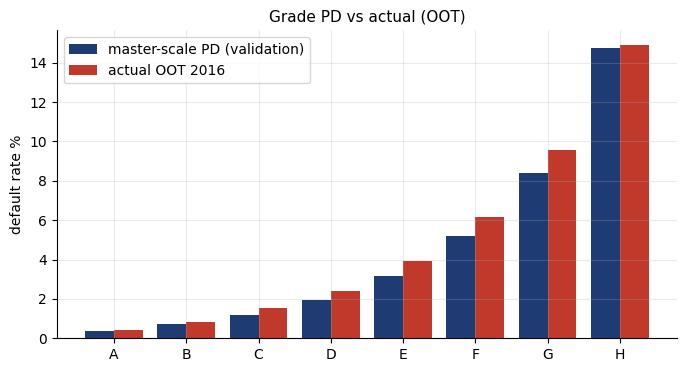

In [22]:
# ---- Master scale (edges fixed on validation) ----------------------------------------------------
K = 8
lo, hi = np.quantile(ch_va, [0.03, 0.97])
edges = np.exp(np.linspace(np.log(lo), np.log(hi), K - 1)).tolist()
g_va, g_oot = L.assign_grade(ch_va, edges), L.assign_grade(ch, edges)
rows = []
for g in range(1, K + 1):
    mv, mo = g_va == g, g_oot == g
    pd_g = float(ch_va[mv].mean()); n = int(mo.sum()); k = int(yoot[mo].sum())
    bt = stats.binomtest(k, n, pd_g) if n else None
    rows.append({"grade": L.grade_letter(g), "grade_index": g, "pd_lower": 0.0 if g == 1 else edges[g - 2], "pd_upper": 1.0 if g == K else edges[g - 1],
                 "master_scale_pd": pd_g, "score_lower": float(L.pd_to_score(1.0 if g == K else edges[g - 1])), "score_upper": float(L.pd_to_score(1e-6 if g == 1 else edges[g - 2])),
                 "share_valid": float(mv.mean()), "share_oot": float(mo.mean()), "n_oot": n, "bads_oot": k, "expected_bads_oot": pd_g * n,
                 "observed_rate_oot": k / n if n else np.nan, "binomial_p_two_sided": bt.pvalue if bt else np.nan,
                 "binomial_p_valid_in_sample": stats.binomtest(int(yva[mv].sum()), int(mv.sum()), pd_g).pvalue,
                 "verdict_oot": ("under-predicted risk" if k / n > pd_g else "over-predicted risk") if (bt and bt.pvalue < 0.05) else "consistent (p>=0.05)"})
ms = pd.DataFrame(rows); save_csv(ms, "master_scale.csv")
save_json({"champion": champion, "n_grades": K, "edges": edges, "grade_pd": ms.master_scale_pd.tolist(), "grades": ms.grade.tolist()}, "master_scale.json")
print(ms[["grade", "pd_lower", "pd_upper", "master_scale_pd", "share_oot", "observed_rate_oot", "binomial_p_two_sided", "verdict_oot"]].round(4).to_string(index=False))
fig, ax = plt.subplots(figsize=(8, 4)); x = np.arange(K)
ax.bar(x - .2, ms.master_scale_pd * 100, .4, color=NAVY, label="master-scale PD (validation)"); ax.bar(x + .2, ms.observed_rate_oot * 100, .4, color=RED, label="actual OOT 2016")
ax.set_xticks(x); ax.set_xticklabels(ms.grade); ax.set_ylabel("default rate %"); ax.legend(); ax.set_title("Grade PD vs actual (OOT)")
savefig(fig, "grade_pd_vs_actual.png", "Blue is what each grade promised (validation), red is what happened in 2016. Grades should be ordered; gaps between the bars show where recalibration would be triggered.")

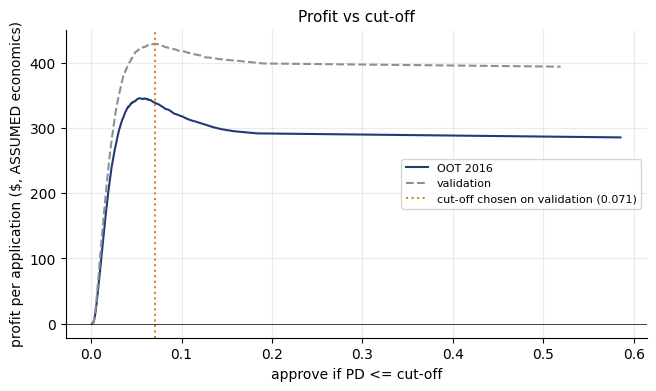

{
 "assumptions": {
  "margin_pct_of_principal": 0.06,
  "lgd": 0.85,
  "ead_pct_of_principal": 0.9,
  "note": "ASSUMED, not observed, on the 12-month horizon of the label. Margin = 12-month net interest margin after funding and servicing cost on a GOOD loan, as % of principal; a BAD loan (90+ DPD inside 12 months, so most principal still outstanding) loses EAD x LGD x principal. Flat pricing: LendingClub risk-based pricing is ignored; losses after month 12 are not in the label."
 },
 "chosen_on": "validation",
 "cutoff_pd": 0.07085777569700538,
 "valid_approval_rate": 0.8862844472600571,
 "valid_bad_rate_approved": 0.0285077576420132,
 "valid_profit_per_application": 428.8038043376996,
 "oot_approval_rate_at_cutoff": 0.8929768723470436,
 "oot_bad_rate_approved": 0.035318457218856215,
 "oot_profit_per_application": 338.34176676291406,
 "oot_profit_approve_all": 285.335868991476,
 "oot_best_possible_cutoff_pd": 0.053453151449115346,
 "mean_loan_amount": 12680.51728525781
}


,margin,lgd,optimal_cutoff_pd_valid,approval_rate_oot,bad_rate_approved_oot,profit_per_app_oot,profit_per_app_oot_approve_all
0,0.03,0.60,0.049,0.763,0.030,122.786,51.892
1,0.03,0.75,0.036,0.615,0.024,98.338,-25.917
2,0.03,0.85,0.036,0.612,0.024,79.849,-77.789
3,0.03,0.95,0.036,0.612,0.024,61.419,-129.661
4,0.06,0.60,0.102,0.963,0.040,430.672,415.016
5,0.06,0.75,0.075,0.906,0.036,375.187,337.208
6,0.06,0.85,0.071,0.893,0.035,338.342,285.336
7,0.06,0.95,0.065,0.870,0.034,306.944,233.464


In [23]:
# ---- Cut-off economics (ASSUMED) -----------------------------------------------------------------
ASSUME = {"margin_pct_of_principal": 0.06, "lgd": 0.85, "ead_pct_of_principal": 0.90,
          "note": "ASSUMED, not observed, on the 12-month horizon of the label. Margin = 12-month net interest margin after funding and servicing cost on a GOOD loan, as % of principal; a BAD loan (90+ DPD inside 12 months, so most principal still outstanding) loses EAD x LGD x principal. Flat pricing: LendingClub risk-based pricing is ignored; losses after month 12 are not in the label."}
amt_va, amt_oot = D.loan_amnt.values[va_idx].astype(float), D.loan_amnt.values[oot_idx].astype(float)
cv = L.cutoff_curve(ch_va, yva, amt_va, ASSUME["margin_pct_of_principal"], ASSUME["lgd"], ASSUME["ead_pct_of_principal"], 300)
co = L.cutoff_curve(ch, yoot, amt_oot, ASSUME["margin_pct_of_principal"], ASSUME["lgd"], ASSUME["ead_pct_of_principal"], 300)
best = cv.loc[cv.profit_per_application.idxmax()]
cut = float(best.cutoff_pd)
o_at = co.iloc[(co.cutoff_pd - cut).abs().argmin()]
cutinfo = {"assumptions": ASSUME, "chosen_on": "validation", "cutoff_pd": cut, "valid_approval_rate": float(best.approval_rate), "valid_bad_rate_approved": float(best.bad_rate_approved),
           "valid_profit_per_application": float(best.profit_per_application), "oot_approval_rate_at_cutoff": float(o_at.approval_rate), "oot_bad_rate_approved": float(o_at.bad_rate_approved),
           "oot_profit_per_application": float(o_at.profit_per_application), "oot_profit_approve_all": float(co.iloc[-1].profit_per_application),
           "oot_best_possible_cutoff_pd": float(co.loc[co.profit_per_application.idxmax()].cutoff_pd), "mean_loan_amount": float(amt_oot.mean())}
save_json(cutinfo, "cutoff.json"); save_csv(co, "cutoff_curve_oot.csv"); save_csv(cv, "cutoff_curve_valid.csv")
sens = []
for mg in (0.03, 0.06, 0.09, 0.12):
    for lg in (0.60, 0.75, 0.85, 0.95):
        c_ = L.cutoff_curve(ch_va, yva, amt_va, mg, lg, ASSUME["ead_pct_of_principal"], 300); b_ = c_.loc[c_.profit_per_application.idxmax()]
        o_ = L.cutoff_curve(ch, yoot, amt_oot, mg, lg, ASSUME["ead_pct_of_principal"], 300); oa = o_.iloc[(o_.cutoff_pd - b_.cutoff_pd).abs().argmin()]
        sens.append({"margin": mg, "lgd": lg, "optimal_cutoff_pd_valid": b_.cutoff_pd, "approval_rate_oot": oa.approval_rate, "bad_rate_approved_oot": oa.bad_rate_approved,
                     "profit_per_app_oot": oa.profit_per_application, "profit_per_app_oot_approve_all": o_.iloc[-1].profit_per_application})
sens = pd.DataFrame(sens); save_csv(sens, "cutoff_sensitivity.csv")
fig, ax = plt.subplots(figsize=(7.5, 4)); ax.plot(co.cutoff_pd, co.profit_per_application, color=NAVY, label="OOT 2016"); ax.plot(cv.cutoff_pd, cv.profit_per_application, color=GREY, ls="--", label="validation")
ax.axvline(cut, color=ORANGE, ls=":", label=f"cut-off chosen on validation ({cut:.3f})"); ax.axhline(0, color="k", lw=.5); ax.set_xlabel("approve if PD <= cut-off"); ax.set_ylabel("profit per application ($, ASSUMED economics)"); ax.legend(fontsize=8)
ax.set_title("Profit vs cut-off"); savefig(fig, "cutoff_profit.png", "Approving everyone is not best; profit peaks where the next-riskiest borrowers cost more in expected loss than they earn. The peak depends heavily on the assumed margin and LGD (see sensitivity table).")
print(json.dumps(cutinfo, indent=1)); sens.round(3).head(8)

In [24]:
# ---- Monitoring plan: thresholds and current status -----------------------------------------------
gini_v = float(vm.loc[champion, "gini"]); row = cmp_.set_index("model").loc[champion]
fails = int((ms.binomial_p_two_sided < 0.05).sum())
trig = [
 {"metric": "Score PSI (train vs current)", "amber": 0.10, "red": 0.25, "current": psi_score["psi_train_vs_oot"]},
 {"metric": "Max input CSI", "amber": 0.10, "red": 0.25, "current": float(csi.csi_train_vs_oot.max())},
 {"metric": "Gini decline vs validation (relative)", "amber": 0.10, "red": 0.20, "current": float(1 - row.oot_gini / gini_v)},
 {"metric": "Calibration: mean predicted PD / actual", "amber": "outside 0.9-1.1", "red": "outside 0.8-1.25", "current": float(row.oot_mean_pred / row.oot_obs_rate)},
 {"metric": "Grades failing binomial test (of 8)", "amber": 2, "red": 4, "current": fails},
]
def status(t):
    c = t["current"]
    if t["metric"].startswith("Calibration"): return "RED" if (c < .8 or c > 1.25) else ("AMBER" if (c < .9 or c > 1.1) else "GREEN")
    return "RED" if c >= t["red"] else ("AMBER" if c >= t["amber"] else "GREEN")
for t in trig: t["status"] = status(t)
mon = {"triggers": trig, "redevelopment_policy": "Recalibrate on a fresh validation window when any metric is AMBER; redevelop and revalidate when any is RED or two are AMBER for two consecutive quarters. Review quarterly; full revalidation at least annually.", "review_frequency": "monthly PSI/CSI, quarterly performance, annual validation"}
save_json(mon, "monitoring_triggers.json"); pd.DataFrame(trig)

,metric,amber,red,current,status
0,Score PSI (train vs current),0.1,0.25,0.001163,GREEN
1,Max input CSI,0.1,0.25,0.047446,GREEN
2,Gini decline vs validation (relative),0.1,0.2,0.101143,AMBER
3,Calibration: mean predicted PD / actual,outside 0.9-1.1,outside 0.8-1.25,0.843377,AMBER
4,Grades failing binomial test (of 8),2,4,5.000000,RED


## Finalise: save models, headline metrics, manifest

All serving logic lives in JSON (bins, coefficients, scaling, preprocessing parameters, XGBoost boosters) so the Streamlit app
can score an applicant **without retraining and without pickles from a different library version**. Joblib copies are also saved.

In [25]:
import joblib
# ---- models -----------------------------------------------------------------------------------------
save_json(sc.to_dict(), "scorecard.json")
save_json(prep.to_dict(), "raw_prep.json"); save_json(prep_all.to_dict(), "tree_prep.json")
save_json({"names": tree_names, "monotone": list(mono_vec)}, "tree_features.json")
joblib.dump({"scorecard": sc, "l2": lr_models["l2"], "l1": lr_models["l1"], "elasticnet": lr_models["elasticnet"], "prep": prep, "woe_map": woe}, MOD / "logistic_ladder.joblib")
joblib.dump(xgb_tuned, MOD / "xgb_tuned.joblib"); joblib.dump(xgb_mono, MOD / "xgb_monotone.joblib")
xgb_tuned.get_booster().save_model(str(MOD / "xgb_tuned.json")); xgb_mono.get_booster().save_model(str(MOD / "xgb_monotone.json"))
save_json({"elasticnet_coef": dict(zip(names_lr, lr_models["elasticnet"].coef_[0])), "elasticnet_intercept": float(lr_models["elasticnet"].intercept_[0])}, "elasticnet_model.json")

# ---- app support files ---------------------------------------------------------------------------
sc_raw_cols = [v for v in L.ALL_FEATURES]
schema = {}
for c in L.NUMERIC_FEATURES:
    xs = Xtr[c]
    schema[c] = {"kind": "num", "label": L.LABELS[c], "group": L.GROUPS[c], "default": None if xs.dropna().empty else float(xs.median()),
                 "min": float(xs.quantile(.005)), "max": float(xs.quantile(.995)), "missing_share": float(xs.isna().mean()), "in_scorecard": c in sc_vars}
for c in L.CATEGORICAL_FEATURES:
    lv = prep_all.cat_params[c]["levels"]; schema[c] = {"kind": "cat", "label": L.LABELS[c], "group": "Applicant", "levels": lv, "default": lv[0], "in_scorecard": c in sc_vars}
save_json(schema, "feature_schema.json")
ex_idx = np.random.default_rng(3).choice(len(oot_idx), 12, replace=False)
exs = []
for i in ex_idx:
    r = Xoot.iloc[i].to_dict()
    exs.append({"features": {k: (None if (isinstance(v, float) and np.isnan(v)) else v) for k, v in r.items()}, "actual_bad": int(yoot[i]), "pd_champion": float(ch[i]), "grade": L.grade_letter(int(g_oot[i]))})
save_json({"examples": exs}, "applicant_examples.json")
scored = pd.DataFrame({"issue_d": D.issue_d.values[oot_idx], "y": yoot, "loan_amnt": amt_oot, "score": S_oot, "grade": [L.grade_letter(int(g)) for g in g_oot]} | {f"pd_{k}": v for k, v in PC_oot.items()} | {"pd_champion": ch})
scored.to_csv(ART / "oot_scored.csv.gz", index=False, compression="gzip")
st = pd.DataFrame({"score": S_va, "y": yva}); st.to_csv(ART / "valid_scored.csv.gz", index=False, compression="gzip")
sbin = pd.DataFrame({"score": np.round(np.linspace(S_oot.min(), S_oot.max(), 40), 1)}); sbin["pd"] = L.score_to_pd(sbin.score)
save_csv(sbin, "score_to_pd_scorecardscale.csv")

# ---- headline metrics.json ---------------------------------------------------------------------------------
c_ = cmp_.set_index("model")
metrics = {
  "project": "LendingClub application PD scorecard (36-month loans)", "champion": champion, "champion_rule_file": "champion_rule.json",
  "data": {"source": "Kaggle wordsforthewise/lending-club accepted_2007_to_2018Q4", "rows_in_file": N_FILE, "snapshot": f"{SNAPSHOT:%b-%Y}", "train_rows_used": int(len(tr_idx)), "train_rows_available": n_train_full,
           "valid_rows": int(len(va_idx)), "oot_rows": int(len(oot_idx)), "sampling_note": SAMPLING_NOTE, "train_window": split.loc[0, "issue_window"], "valid_window": split.loc[1, "issue_window"], "oot_window": "Jan-2016 to Dec-2016",
           "bad_rate_train": float(ytr.mean()), "bad_rate_valid": float(yva.mean()), "bad_rate_oot": float(yoot.mean()), "n_features_candidate": len(L.ALL_FEATURES), "n_pass_iv": len(keep0), "n_after_corr": len(keep1), "n_after_vif": len(keep2), "n_scorecard_vars": len(sc_vars)},
  "oot": {k: {m: float(c_.loc[k, f"oot_{m}"]) for m in ("auc", "gini", "ks", "pr_auc", "brier", "ece")} | {"auc_ci": [float(c_.loc[k, "auc_ci_low"]), float(c_.loc[k, "auc_ci_high"])], "role": c_.loc[k, "role"]} for k in c_.index},
  "valid": {k: {"auc": float(vm.loc[k, "auc"]), "gini": float(vm.loc[k, "gini"]), "ks": float(vm.loc[k, "ks"]), "brier": float(vm.loc[k, "brier"]), "ece": float(vm.loc[k, "ece"])} for k in vm.index},
  "psi": psi_score, "label_sensitivity": cens, "cutoff": cutinfo, "bootstrap_reps": BOOT, "scorecard": {"pdo": L.PDO, "base_score": L.BASE_SCORE, "base_odds": L.BASE_ODDS},
  "monitoring_status": {t["metric"]: t["status"] for t in trig}, "n_grades_failing_binomial_oot": fails,
  "runtime_minutes": round((time.time() - T0) / 60, 1), "fast_mode": FAST}
save_json(metrics, "metrics.json"); save_json(CAPTIONS, "figure_captions.json")
save_json({"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__, "sklearn": sklearn.__version__, "xgboost": xgboost.__version__, "optbinning": optbinning.__version__,
           "statsmodels": sm.__version__, "shap": shap.__version__, "platform": platform.platform(), "on_kaggle": ON_KAGGLE, "runtime_minutes": metrics["runtime_minutes"]}, "environment.json")
shutil.copy("lcpd_lib.py", ART / "lcpd_lib.py")
man = [{"file": str(p.relative_to(ART)).replace(os.sep, "/"), "kb": round(p.stat().st_size / 1024, 1)} for p in sorted(ART.rglob("*")) if p.is_file()]
save_json({"files": man, "n_files": len(man)}, "MANIFEST.json")
tick(f"DONE. {len(man)} artifact files; champion = {champion}")
pd.DataFrame(man).tail(8)

[  18.2 min] DONE. 98 artifact files; champion = xgb_monotone


,file,kb
90,tree_prep.json,14.9
91,valid_scored.csv.gz,907.3
92,vif_final.csv,1.1
93,vif_iterations.csv,0.0
94,vintage_curves.csv,5.4
95,woe_bins.csv,33.6
96,xgb_best_params.json,0.2
97,xgb_search.csv,0.9
